Installation of Libraries


In [1]:
!pip -q install decord opencv-python-headless matplotlib pandas tqdm num2words

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Downloading of Dataset (Something-Something-V2)

In [9]:
import os, subprocess
from google.colab import drive
drive.mount("/content/drive")

DEST = "/content/drive/MyDrive/ssv2"; os.makedirs(DEST, exist_ok=True)
PARTS = ["00", "01"]   # ~1 GB each; add "02","03" later if a class has too few clips
V2 = "https://apigwx-aws.qualcomm.com/qsc/public/v1/api/download/software/dataset/AIDataset/Something-Something-V2/20bn-something-something-v2-"
LABELS = "https://softwarecenter.qualcomm.com/api/download/software/dataset/AIDataset/Something-Something-V2/20bn-something-something-download-package-labels.zip"

jobs = [(LABELS, "20bn-something-something-download-package-labels.zip")] + [(V2 + p, f"20bn-something-something-v2-{p}") for p in PARTS]
for url, name in jobs:
    out = f"{DEST}/{name}"
    if os.path.exists(out) and os.path.getsize(out) > 1e5:   # skip finished files
        print("have", name); continue
    r = subprocess.run(f"wget -c -q --show-progress -O '{out}' '{url}'", shell=True)
    print(name, "OK" if r.returncode == 0 else f"FAILED (code {r.returncode})")

!ls -lh /content/drive/MyDrive/ssv2
!head -c 300 /content/drive/MyDrive/ssv2/20bn-something-something-v2-00 | file -   # should say gzip data, not HTML

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
have 20bn-something-something-download-package-labels.zip
20bn-something-something-v2-00 OK
20bn-something-something-v2-01 OK
total 19G
-rw------- 1 root root 5.0M Sep 23  2024 20bn-something-something-download-package-labels.zip
-rw------- 1 root root 9.4G Aug 27  2024 20bn-something-something-v2-00
-rw------- 1 root root 8.8G Aug 27  2024 20bn-something-something-v2-01
/dev/stdin: gzip compressed data, last modified: Wed Dec 20 09:42:09 2017, from Unix


In [11]:
import os, glob, json, zipfile, subprocess, random, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.format import open_memmap
from google.colab import drive
drive.mount("/content/drive")

SRC = "/content/drive/MyDrive/ssv2"
DST = "/content/ssv2"; os.makedirs(DST, exist_ok=True)
OUT = "/content/results"; os.makedirs(OUT, exist_ok=True)
CACHE = "/content/cache"; os.makedirs(CACHE, exist_ok=True)

SEED = 0; random.seed(SEED); np.random.seed(SEED)
N_FRAMES = 16            # SSv2 clips are ~3-6s at 12fps (~40-70 frames); 16 uniform samples cover the whole action
IMG = 224                # DINOv2/CLIP input size; squash-resize so the moving object is never cropped out
MAX_TRAIN, MAX_VAL = 150, 40   # per class: ~1900 clips total; frames go to a disk memmap (~4.6GB) so RAM stays low

# reversal pairs adjacent; last two are near-static controls
TARGETS = {
    "Opening [something]": "opening", "Closing [something]": "closing",
    "Moving [something] up": "move_up", "Moving [something] down": "move_down",
    "Pushing [something] from left to right": "push_L2R", "Pushing [something] from right to left": "push_R2L",
    "Putting [something] into [something]": "put_into", "Taking [something] out of [something]": "take_out",
    "Holding [something]": "holding", "Showing [something] to the camera": "showing",
}
SHORT = list(TARGETS.values())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# ---------- 1. labels -> choose subset BEFORE extracting anything
lab_zip = [p for p in glob.glob(f"{SRC}/*") if "label" in os.path.basename(p).lower() and zipfile.is_zipfile(p)]
assert lab_zip, f"no labels zip in {SRC}: {os.listdir(SRC)}"
if not glob.glob(f"{DST}/labels_pkg/**/train.json", recursive=True):
    zipfile.ZipFile(lab_zip[0]).extractall(f"{DST}/labels_pkg")
jpath = lambda n: glob.glob(f"{DST}/labels_pkg/**/{n}", recursive=True)[0]
train_json, val_json = json.load(open(jpath("train.json"))), json.load(open(jpath("validation.json")))

def pick(items, cap, split):
    rows = []
    for tpl, short in TARGETS.items():
        ids = [it for it in items if it["template"] == tpl]
        random.Random(SEED).shuffle(ids)
        rows += [dict(id=it["id"], cls=short, split=split, text=it["label"]) for it in ids[:cap]]
    return rows
df = pd.DataFrame(pick(train_json, MAX_TRAIN, "train") + pick(val_json, MAX_VAL, "val"))
print("selected:", len(df)); print(df.groupby(["cls", "split"]).size().unstack(fill_value=0).reindex(SHORT).to_string())

selected: 1900
split      train  val
cls                  
opening      150   40
closing      150   40
move_up      150   40
move_down    150   40
push_L2R     150   40
push_R2L     150   40
put_into     150   40
take_out     150   40
holding      150   40
showing      150   40


In [13]:
# ---------- 2. stream-extract ONLY selected videos from the concatenated tar.gz (skipped if already done)
DST = "/content/drive/MyDrive/ssv2_frames"; os.makedirs(DST, exist_ok=True)

VROOT = f"{DST}/20bn-something-something-v2"
have = set(os.path.basename(p)[:-5] for p in glob.glob(f"{VROOT}/*.webm")) if os.path.isdir(VROOT) else set()
if not set(df.id) <= have:
    parts = sorted(glob.glob(f"{SRC}/20bn-something-something-v2-??"))
    assert parts, "video parts missing"
    with open(f"{DST}/members.txt", "w") as f:
        f.write("\n".join(f"20bn-something-something-v2/{i}.webm" for i in df.id))
    print("extracting (reads ~19GB stream once, ~10-20 min)...")
    subprocess.run(f"cat {' '.join(parts)} | tar -xzf - -C {DST} -T {DST}/members.txt", shell=True)
df["path"] = [f"{VROOT}/{i}.webm" for i in df.id]
missing = [p for p in df.path if not os.path.exists(p)]
print("extracted:", len(df) - len(missing), "| missing:", len(missing))
df = df[df.path.map(os.path.exists)].reset_index(drop=True)

extracting (reads ~19GB stream once, ~10-20 min)...
extracted: 1900 | missing: 0


In [6]:
# ---------- 3. load ordered frames -> memmap, with integrity checks
def load_clip(path, n=N_FRAMES, size=IMG):
    cap = cv2.VideoCapture(path); fr, ts = [], []
    while True:                                   # sequential decode: OpenCV seeking in webm is unreliable
        ok, f = cap.read()
        if not ok: break
        fr.append(f); ts.append(cap.get(cv2.CAP_PROP_POS_MSEC))
    fps = cap.get(cv2.CAP_PROP_FPS); cap.release()
    meta = dict(n_decoded=len(fr), fps=fps, h=fr[0].shape[0] if fr else 0, w=fr[0].shape[1] if fr else 0)
    if len(fr) < n: return None, None, meta, ts
    idx = np.linspace(0, len(fr) - 1, n).round().astype(int)   # uniform sampling, temporal order preserved
    return np.stack([cv2.cvtColor(cv2.resize(fr[i], (size, size)), cv2.COLOR_BGR2RGB) for i in idx]), idx, meta, ts

def integrity_ok(idx, ts, n=N_FRAMES):
    return len(idx) == n and bool(np.all(np.diff(idx) > 0)) and all(b >= a for a, b in zip(ts, ts[1:]))

def motion(fr):  # mean abs diff between consecutive sampled frames
    g = fr.astype(np.float32).mean(-1)
    return float(np.mean([np.abs(g[i+1] - g[i]).mean() for i in range(len(g) - 1)]))

X = open_memmap(f"{CACHE}/frames.npy", mode="w+", dtype=np.uint8, shape=(len(df), N_FRAMES, IMG, IMG, 3))  # row i <-> df row i
recs = []
for i, r in tqdm(df.iterrows(), total=len(df), desc="loading"):
    fr, idx, meta, ts = load_clip(r.path)
    ok = fr is not None and integrity_ok(idx, ts)
    if ok: X[i] = fr
    recs.append(dict(**meta, valid=ok, motion=motion(fr) if ok else np.nan,
                     first_last=float(np.abs(fr[0].astype(np.float32) - fr[-1].astype(np.float32)).mean()) if ok else np.nan))
X.flush()
df = pd.concat([df, pd.DataFrame(recs)], axis=1)
df["dur_s"] = df.n_decoded / df.fps
df.to_csv(f"{OUT}/dataset_index.csv", index=False)    # X rows align with this csv; ALWAYS filter by valid, never drop rows
print(f"\nclips: {len(df)} | valid: {int(df.valid.sum())} | dropped: {int((~df.valid).sum())}")
V = df[df.valid]                                       # keeps original index -> still addresses X rows
print(V[["n_decoded", "fps", "dur_s", "h", "w"]].describe().round(2).to_string())


loading: 100%|██████████| 1900/1900 [02:03<00:00, 15.42it/s]



clips: 1900 | valid: 1890 | dropped: 10
       n_decoded     fps    dur_s       h        w
count    1890.00  1890.0  1890.00  1890.0  1890.00
mean       45.03    12.0     3.75   240.0   387.85
std        12.19     0.0     1.02     0.0    52.59
min        16.00    12.0     1.33   240.0   293.00
25%        36.00    12.0     3.00   240.0   320.00
50%        45.00    12.0     3.75   240.0   427.00
75%        55.00    12.0     4.58   240.0   427.00
max        73.00    12.0     6.08   240.0   436.00


In [7]:
bad = df[~df.valid]
print("fewer than 16 frames:", int((bad.n_decoded < 16).sum()), "of", len(bad))
print(bad[["id", "cls", "split", "n_decoded"]].to_string())

fewer than 16 frames: 10 of 10
          id        cls  split  n_decoded
83    155911    opening  train         14
191    72174    closing  train         15
240   219683    closing  train         15
442    94569    move_up  train         14
525     3463  move_down  train         15
1249  204650    holding  train         14
1265  144749    holding  train         14
1282  112417    holding  train         15
1304  103802    holding  train         14
1317  179772    holding  train         15


In [8]:
# ---------- 4. ordering sanity check
rng = np.random.RandomState(SEED); sel = V.index[:100]
o = [motion(X[j]) for j in sel]; s = [motion(X[j][rng.permutation(N_FRAMES)]) for j in sel]
print(f"\nordering check: adjacent diff ordered={np.mean(o):.2f} < shuffled={np.mean(s):.2f} -> {np.mean(o) < np.mean(s)}")



ordering check: adjacent diff ordered=17.45 < shuffled=35.05 -> True


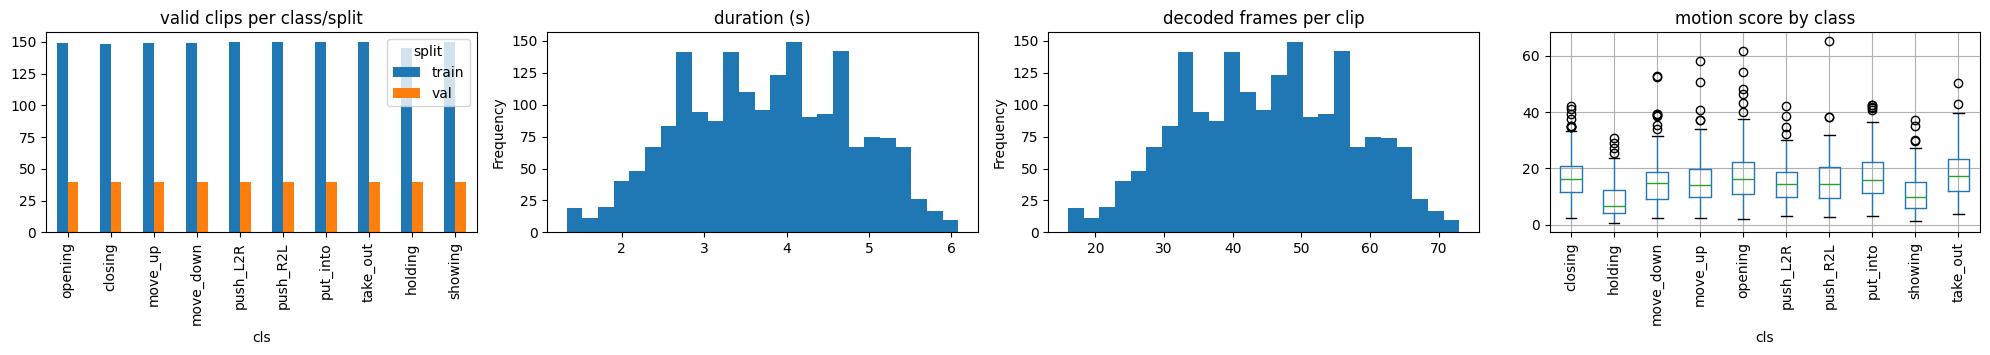

In [9]:
# ---------- 5. stats plots
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
V.groupby(["cls", "split"]).size().unstack(fill_value=0).reindex(SHORT).plot.bar(ax=ax[0], title="valid clips per class/split")
V.dur_s.plot.hist(bins=25, ax=ax[1], title="duration (s)")
V.n_decoded.plot.hist(bins=25, ax=ax[2], title="decoded frames per clip")
V.boxplot(column="motion", by="cls", ax=ax[3], rot=90); ax[3].set_title("motion score by class"); plt.suptitle("")
plt.tight_layout(); plt.savefig(f"{OUT}/dataset_stats.png", dpi=150); plt.show()


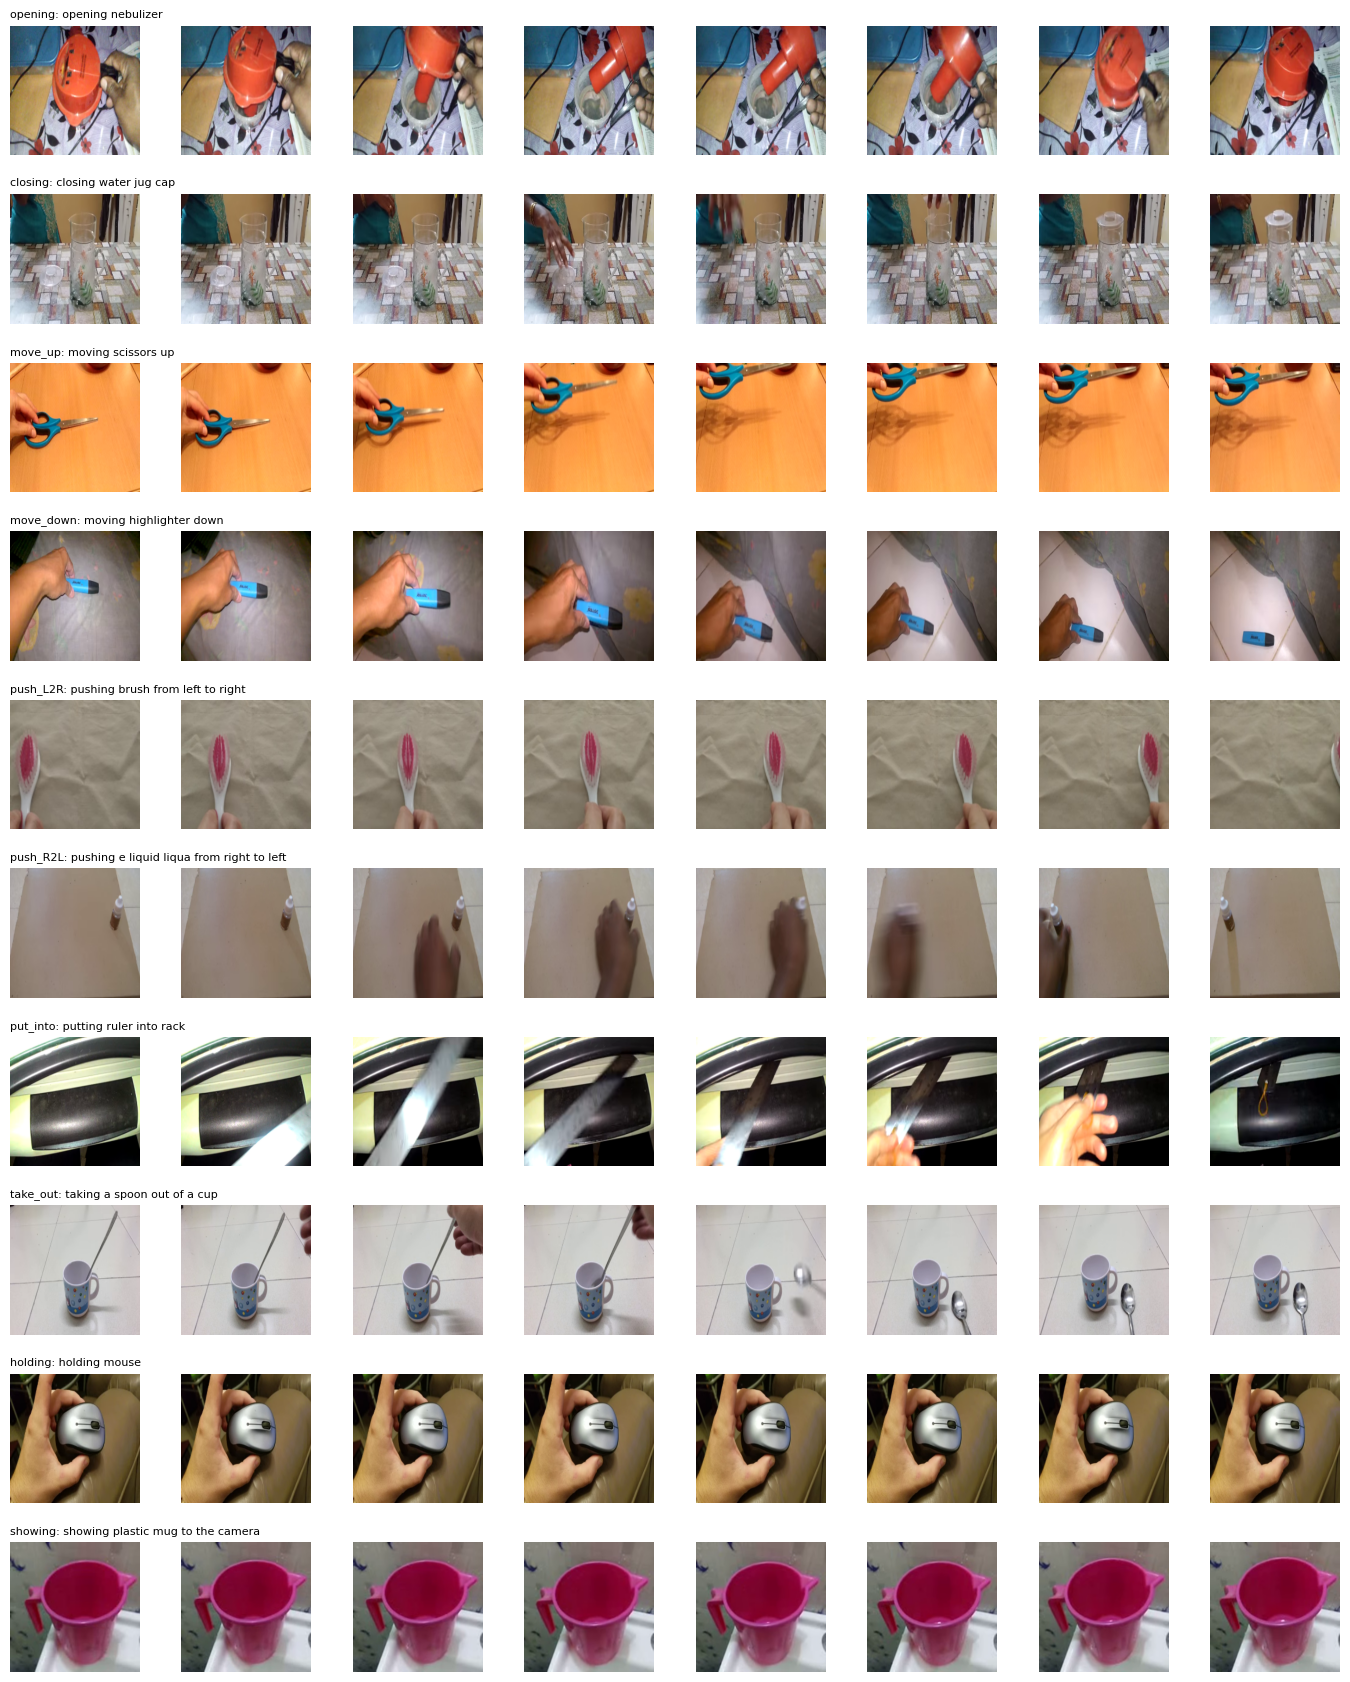

In [10]:
# ---------- 6. frame strips: 1 train clip per class (pairs adjacent), 8 of 16 frames
COLS = 8; ts8 = np.linspace(0, N_FRAMES - 1, COLS).astype(int)
fig, axes = plt.subplots(len(SHORT), COLS, figsize=(COLS * 1.7, len(SHORT) * 1.7))
for r, c in enumerate(SHORT):
    j = V[(V.cls == c) & (V.split == "train")].index[0]
    for k, t in enumerate(ts8): axes[r, k].imshow(X[j][t]); axes[r, k].axis("off")
    axes[r, 0].set_title(f"{c}: {df.text[j][:45]}", fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/frame_strips_per_class.png", dpi=130); plt.show()


mean motion / first-last diff per class:
           motion  first_last
cls                          
opening     17.89       47.63
closing     17.21       46.33
move_up     15.89       46.12
move_down   15.39       44.74
push_L2R    15.10       40.25
push_R2L    15.59       40.94
put_into    17.34       34.87
take_out    18.37       38.85
holding      8.62       27.53
showing     11.23       29.70


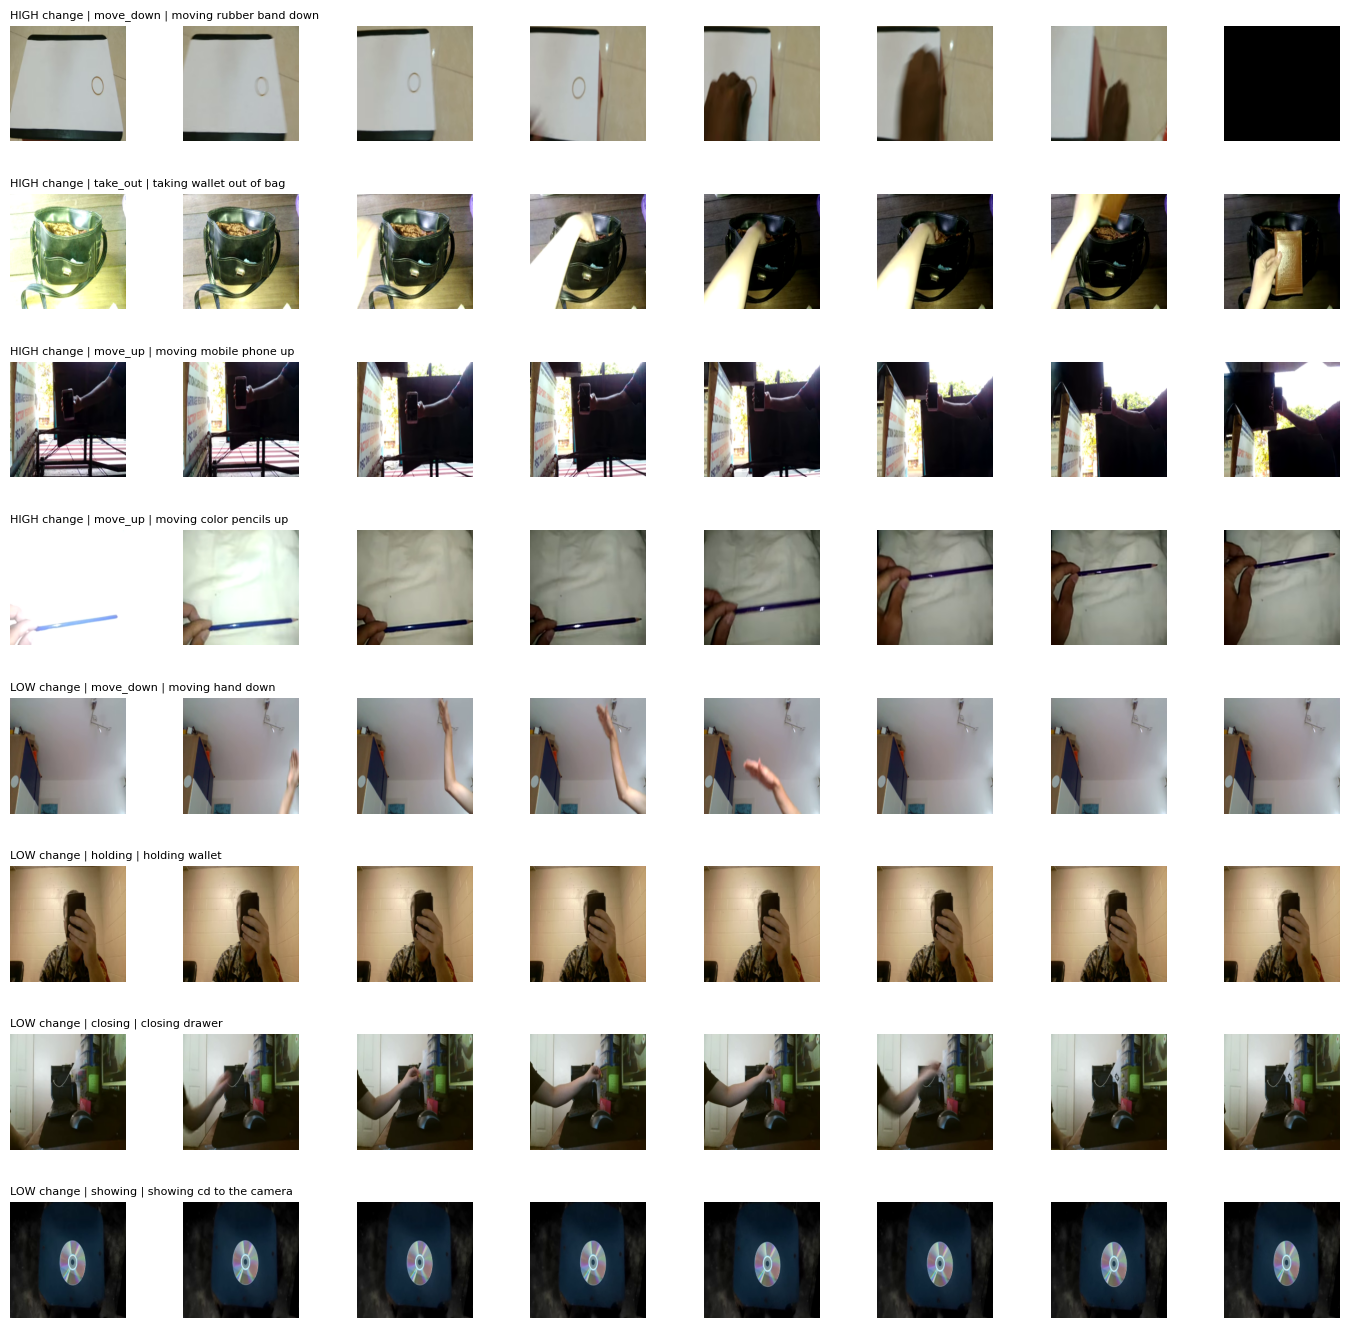

In [11]:
# ---------- 7. where is temporal info likely useful? (high first-last change vs near-static)
print("\nmean motion / first-last diff per class:")
print(V.groupby("cls")[["motion", "first_last"]].mean().round(2).reindex(SHORT).to_string())
hi, lo = V.sort_values("first_last", ascending=False).head(4), V.sort_values("first_last").head(4)
fig, axes = plt.subplots(8, COLS, figsize=(COLS * 1.7, 8 * 1.7))
for r, (j, row) in enumerate(list(hi.iterrows()) + list(lo.iterrows())):
    for k, t in enumerate(ts8): axes[r, k].imshow(X[j][t]); axes[r, k].axis("off")
    axes[r, 0].set_title(f"{'HIGH' if r < 4 else 'LOW'} change | {row.cls} | {row.text[:40]}", fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/high_vs_low_change.png", dpi=130); plt.show()

In [12]:
!pip -q install scikit-learn

In [16]:
import os, gc, sys, shutil, subprocess, numpy as np, pandas as pd, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from tqdm import tqdm
from google.colab import drive
drive.mount("/content/drive")

BACKUP = "/content/drive/MyDrive/ssv2_out"; CACHE, OUT = "/content/cache", "/content/results"
if not os.path.exists(f"{CACHE}/frames.npy"):          # fresh runtime: restore frames + results from Drive (~4.6GB, a few minutes)
    shutil.copytree(f"{BACKUP}/cache", CACHE, dirs_exist_ok=True); shutil.copytree(f"{BACKUP}/results", OUT, dirs_exist_ok=True)
os.makedirs(OUT, exist_ok=True)
assert torch.cuda.is_available(), "No GPU attached: Runtime > Change runtime type > T4 GPU, then rerun"
dev = "cuda"; SEED = 0; rng = np.random.RandomState(SEED)
print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4


In [17]:
df = pd.read_csv(f"{OUT}/dataset_index.csv"); FR = np.load(f"{CACHE}/frames.npy", mmap_mode="r")   # FR[i, t] = frame t of clip i, 224x224 RGB
V = df[df.valid]; vidx = V.index.values; N, T = FR.shape[:2]; lab = V.cls.values                      # lab = class name of each valid clip
SHORT = ["opening","closing","move_up","move_down","push_L2R","push_R2L","put_into","take_out","holding","showing"]
PAIRS = [("opening","closing"),("move_up","move_down"),("push_L2R","push_R2L"),("put_into","take_out")]   # time-reversal pairs
PARTNER_NAME = {a: b for a, b in PAIRS} | {b: a for a, b in PAIRS}
print(f"{len(vidx)} valid clips x {T} frames = {len(vidx) * T} frames to embed")

1890 valid clips x 16 frames = 30240 frames to embed


In [18]:
from transformers import AutoModel, CLIPVisionModel, SiglipVisionModel
from transformers.utils import logging as hf_logging; hf_logging.set_verbosity_error()   # hides harmless "UNEXPECTED text_model.*" load reports
CPB = 8                                                       # clips per batch -> 128 frames per forward pass; lower if CUDA OOM
IMAGENET = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]); CLIP_MS = ([0.4815, 0.4578, 0.4082], [0.2686, 0.2613, 0.2758])
ENC = {"dino":   dict(id="facebook/dinov2-base",           ms=IMAGENET,             loader=AutoModel),          # self-supervised, spatially rich
       "clip":   dict(id="openai/clip-vit-base-patch16",   ms=CLIP_MS,              loader=CLIPVisionModel),    # language-aligned
       "siglip": dict(id="google/siglip-base-patch16-224", ms=([.5] * 3, [.5] * 3), loader=SiglipVisionModel)}  # language-aligned (sigmoid loss)

def run(model, key, x):       # -> (global embedding [B,D], patch tokens [B,P,D])
    if key == "dino":   h = model(pixel_values=x).last_hidden_state;  return h[:, 0], h[:, 1:]                    # CLS token
    if key == "clip":   o = model(pixel_values=x);                    return o.pooler_output, o.last_hidden_state[:, 1:]   # post-LN CLS token
    if key == "siglip": o = model(pixel_values=x);                    return o.pooler_output, o.last_hidden_state          # attention-pooling head (no CLS token)

def extract(key):
    cfg = ENC[key]; paths = {n: f"{CACHE}/{key}_{n}.npy" for n in ["cls", "patchmean", "grid2x2"]}
    if all(os.path.exists(p) for p in paths.values()): print(key, ": cached"); return
    model = cfg["loader"].from_pretrained(cfg["id"]).to(dev).eval().half(); dtype = torch.float16
    mean = torch.tensor(cfg["ms"][0], device=dev).view(1, 3, 1, 1); std = torch.tensor(cfg["ms"][1], device=dev).view(1, 3, 1, 1)
    for s in tqdm(range(0, len(vidx), CPB), desc=key):
        ids_ = vidx[s:s + CPB]; b = len(ids_)
        x = torch.from_numpy(np.stack([FR[i] for i in ids_])).to(dev).reshape(b * T, 224, 224, 3).permute(0, 3, 1, 2).float() / 255
        x = (x - mean) / std
        with torch.no_grad():
            g, p = run(model, key, x.to(dtype))
            if dtype == torch.float16 and not torch.isfinite(g).all():          # fp16 overflow guard: redo in fp32
                print(key, ": fp16 gave non-finite values -> fp32"); model.float(); dtype = torch.float32; g, p = run(model, key, x.to(dtype))
        g, p = g.float(), p.float(); hw = int(round(p.shape[1] ** 0.5))         # patch grid side (14 or 16)
        gr = F.adaptive_avg_pool2d(p.reshape(b * T, hw, hw, -1).permute(0, 3, 1, 2), 2)   # coarse 2x2 spatial grid (kept for later sections)
        if s == 0:
            D = g.shape[-1]; A = {"cls": np.zeros((N, T, D), np.float16), "patchmean": np.zeros((N, T, D), np.float16), "grid2x2": np.zeros((N, T, 4, D), np.float16)}
        A["cls"][ids_] = g.reshape(b, T, -1).cpu().numpy(); A["patchmean"][ids_] = p.mean(1).reshape(b, T, -1).cpu().numpy()
        A["grid2x2"][ids_] = gr.flatten(2).permute(0, 2, 1).reshape(b, T, 4, -1).cpu().numpy()
    for n, a in A.items(): np.save(paths[n], a)
    del model; gc.collect(); torch.cuda.empty_cache()

for key in ENC:
    try: extract(key)
    except Exception as e: print(f"!! {key} skipped: {type(e).__name__}: {str(e)[:300]}"); gc.collect(); torch.cuda.empty_cache()

dino : cached
clip : cached
siglip : cached


In [19]:
import glob, importlib
subprocess.run("pip -q install einops timm safetensors", shell=True)
from huggingface_hub import snapshot_download
from safetensors.torch import load_file
CPB_INT = 4                                  # 448px = 1025 tokens/frame; 4 clips = 64 frames per batch fits a T4 in fp16 (use 2 on OOM)
MID, RES = "OpenGVLab/InternViT-300M-448px", 448
src = snapshot_download(MID); pkg = "/content/internvit_pkg"; os.makedirs(pkg, exist_ok=True)
for f in os.listdir(src):
    if f.endswith(".py"): shutil.copy(os.path.join(src, f), pkg)
open(f"{pkg}/__init__.py", "a").close(); sys.path.insert(0, "/content"); importlib.invalidate_caches()
m = importlib.import_module("internvit_pkg.modeling_intern_vit")
c = m.InternVisionConfig.from_pretrained(src); c.use_flash_attn = False                 # flash-attn is unusable on a T4
model = m.InternVisionModel(c); sd = {}
for f in sorted(glob.glob(f"{src}/*.safetensors")): sd.update(load_file(f))
miss, unexp = model.load_state_dict(sd, strict=False); print("missing:", len(miss), miss[:3], "| unexpected:", len(unexp)); assert len(miss) == 0
model = model.to(dev).eval().half(); dtype = torch.float16
mean = torch.tensor(CLIP_MS[0], device=dev).view(1, 3, 1, 1); std = torch.tensor(CLIP_MS[1], device=dev).view(1, 3, 1, 1)
def run_int(x):
    o = model(x); h = o.last_hidden_state if hasattr(o, "last_hidden_state") else o[0]; return h[:, 0], h[:, 1:]
for s in tqdm(range(0, len(vidx), CPB_INT), desc="internvit"):
    ids_ = vidx[s:s + CPB_INT]; b = len(ids_)
    x = torch.from_numpy(np.stack([FR[i] for i in ids_])).to(dev).reshape(b * T, 224, 224, 3).permute(0, 3, 1, 2).float() / 255
    x = (F.interpolate(x, size=RES, mode="bicubic", align_corners=False).clamp(0, 1) - mean) / std    # frames are cached at 224, so this upsamples (adds no detail)
    with torch.no_grad():
        g, p = run_int(x.to(dtype))
        if dtype == torch.float16 and not torch.isfinite(g).all(): print("fp16 non-finite -> fp32"); model.float(); dtype = torch.float32; g, p = run_int(x.to(dtype))
    g, p = g.float(), p.float(); hw = int(round(p.shape[1] ** 0.5)); gr = F.adaptive_avg_pool2d(p.reshape(b * T, hw, hw, -1).permute(0, 3, 1, 2), 2)
    if s == 0:
        D = g.shape[-1]; A = {"cls": np.zeros((N, T, D), np.float16), "patchmean": np.zeros((N, T, D), np.float16), "grid2x2": np.zeros((N, T, 4, D), np.float16)}
    A["cls"][ids_] = g.reshape(b, T, -1).cpu().numpy(); A["patchmean"][ids_] = p.mean(1).reshape(b, T, -1).cpu().numpy()
    A["grid2x2"][ids_] = gr.flatten(2).permute(0, 2, 1).reshape(b, T, 4, -1).cpu().numpy()
for n, a in A.items(): np.save(f"{CACHE}/internvit_{n}.npy", a)
del model; gc.collect(); torch.cuda.empty_cache(); print("internvit saved")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

missing: 0 [] | unexpected: 0




internvit:   0%|          | 0/473 [00:00<?, ?it/s]

internvit:   0%|          | 1/473 [00:06<50:56,  6.48s/it]

internvit:   0%|          | 2/473 [00:13<51:39,  6.58s/it]

internvit:   1%|          | 3/473 [00:19<52:11,  6.66s/it]

internvit:   1%|          | 4/473 [00:26<51:43,  6.62s/it]

internvit:   1%|          | 5/473 [00:32<50:24,  6.46s/it]

internvit:   1%|▏         | 6/473 [00:38<48:52,  6.28s/it]

internvit:   1%|▏         | 7/473 [00:44<47:33,  6.12s/it]

internvit:   2%|▏         | 8/473 [00:50<46:33,  6.01s/it]

internvit:   2%|▏         | 9/473 [00:55<45:39,  5.90s/it]

internvit:   2%|▏         | 10/473 [01:01<45:11,  5.86s/it]

internvit:   2%|▏         | 11/473 [01:07<44:41,  5.80s/it]

internvit:   3%|▎         | 12/473 [01:13<44:39,  5.81s/it]

internvit:   3%|▎         | 13/473 [01:18<44:42,  5.83s/it]

internvit:   3%|▎         | 14/473 [01:24<45:06,  5.90s/it]

internvit:   3%|▎         | 15/473 [01:31<45:41,  5.99s/it]

internvit:   3%|▎         | 16/473 [01:3

internvit saved


In [20]:
ENCODERS = [k for k in ["dino", "clip", "siglip", "internvit"] if os.path.exists(f"{CACHE}/{k}_cls.npy")]
EMB = {k: np.load(f"{CACHE}/{k}_cls.npy")[vidx].astype(np.float32) for k in ENCODERS}      # EMB[k][clip, t] = E_(t+1), the embedding of frame t+1
unit = lambda a: a / np.linalg.norm(a, axis=-1, keepdims=True)                                # scale vectors to length 1 so a dot product = cosine similarity
EN = {k: unit(E) for k, E in EMB.items()}
print({k: v.shape for k, v in EMB.items()}, " = (clips, frames, embedding dim)")

{'dino': (1890, 16, 768), 'clip': (1890, 16, 768), 'siglip': (1890, 16, 768), 'internvit': (1890, 16, 1024)}  = (clips, frames, embedding dim)


background similarity (random frames, different clips): {'dino': 0.111, 'clip': 0.501, 'siglip': 0.604, 'internvit': 0.992}

consecutive-frame similarity (rescaled):
            dino   clip  siglip  internvit
opening    0.880  0.846   0.851      0.735
closing    0.882  0.847   0.854      0.749
move_up    0.886  0.848   0.862      0.673
move_down  0.882  0.846   0.857      0.620
push_L2R   0.902  0.859   0.869      0.620
push_R2L   0.896  0.856   0.862      0.644
put_into   0.889  0.851   0.861      0.823
take_out   0.878  0.837   0.851      0.836
holding    0.949  0.924   0.925      0.877
showing    0.938  0.911   0.906      0.803

first-vs-last-frame similarity (rescaled):
            dino   clip  siglip  internvit
opening    0.535  0.524   0.544      0.396
closing    0.521  0.512   0.557      0.444
move_up    0.629  0.566   0.608      0.467
move_down  0.612  0.549   0.599      0.206
push_L2R   0.687  0.618   0.651      0.512
push_R2L   0.691  0.640   0.651      0.374
put_into   0.690

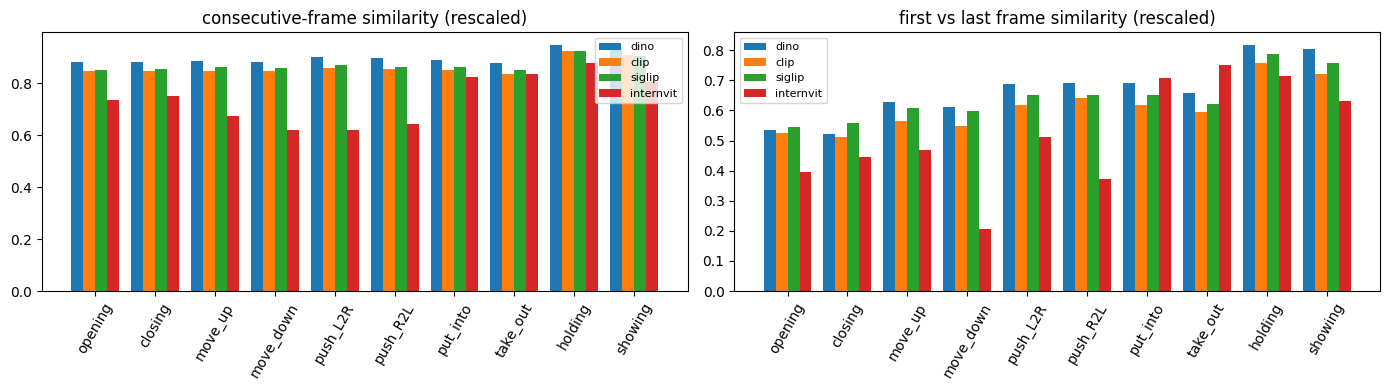

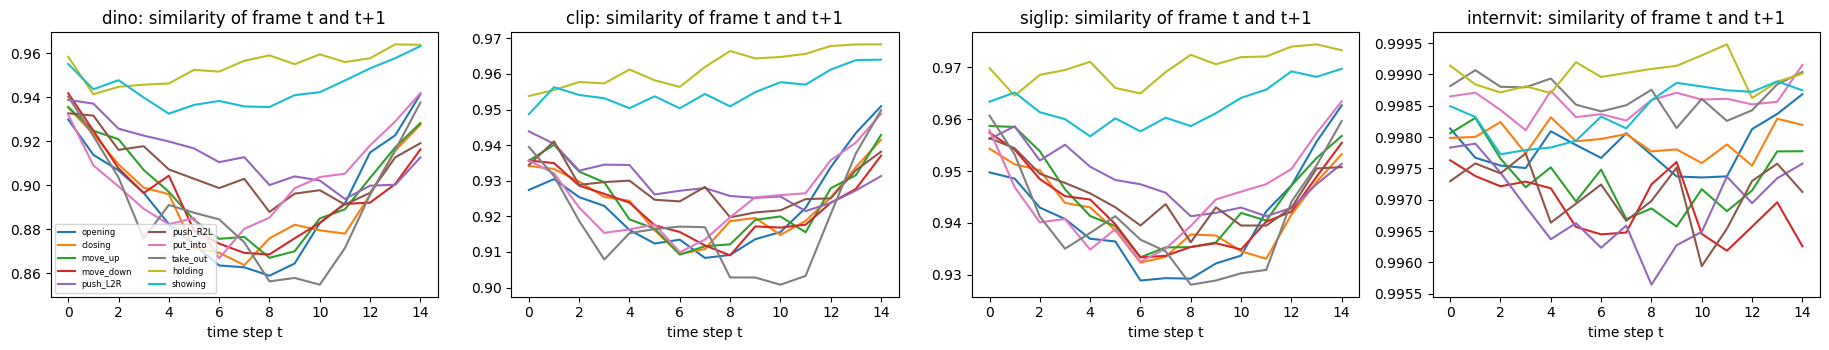

In [21]:
def background(En, n=20000):          # mean cos-sim between random frames of DIFFERENT clips: each encoder's "unrelated images" floor
    i, j = rng.randint(0, len(En), n), rng.randint(0, len(En), n); k = i != j
    return float((En[i[k], rng.randint(0, T, k.sum())] * En[j[k], rng.randint(0, T, k.sum())]).sum(-1).mean())
rescale = lambda s, b: (s - b) / (1 - b)            # 0 = as similar as random frames, 1 = identical

CONS, raw_c, cons_n, fl_n, base = {}, {}, {}, {}, {}
for k, En in EN.items():
    cons = (En[:, 1:] * En[:, :-1]).sum(-1)         # [clips, 15] consecutive-frame cosine similarity
    fl = (En[:, 0] * En[:, -1]).sum(-1)             # [clips]     first-vs-last-frame cosine similarity
    b = background(En); base[k] = b; CONS[k] = cons
    raw_c[k] = [cons[lab == c].mean() for c in SHORT]
    cons_n[k] = [rescale(cons[lab == c].mean(), b) for c in SHORT]; fl_n[k] = [rescale(fl[lab == c].mean(), b) for c in SHORT]
print("background similarity (random frames, different clips):", {k: round(v, 3) for k, v in base.items()})
print("\nconsecutive-frame similarity (rescaled):"); print(pd.DataFrame(cons_n, index=SHORT).round(3).to_string())
print("\nfirst-vs-last-frame similarity (rescaled):"); print(pd.DataFrame(fl_n, index=SHORT).round(3).to_string())
pd.DataFrame(raw_c, index=SHORT).round(4).to_csv(f"{OUT}/cosine_consecutive_raw.csv")
pd.DataFrame(cons_n, index=SHORT).round(4).to_csv(f"{OUT}/cosine_consecutive_rescaled.csv"); pd.DataFrame(fl_n, index=SHORT).round(4).to_csv(f"{OUT}/cosine_first_last_rescaled.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4)); w = 0.8 / len(ENCODERS)
for a, (title, d) in zip(ax, [("consecutive-frame similarity (rescaled)", cons_n), ("first vs last frame similarity (rescaled)", fl_n)]):
    for j, k in enumerate(ENCODERS): a.bar(np.arange(10) + w * (j - (len(ENCODERS) - 1) / 2), d[k], w, label=k)
    a.set_xticks(range(10)); a.set_xticklabels(SHORT, rotation=60); a.set_title(title); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_cosine_by_class.png", dpi=150); plt.show()
fig, ax = plt.subplots(1, len(ENCODERS), figsize=(4.6 * len(ENCODERS), 3.6), squeeze=False)
for a, k in zip(ax[0], ENCODERS):
    for c in SHORT: a.plot(CONS[k][lab == c].mean(0), label=c)
    a.set_title(f"{k}: similarity of frame t and t+1"); a.set_xlabel("time step t")
ax[0][0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.savefig(f"{OUT}/fig_cosine_over_time.png", dpi=150); plt.show()

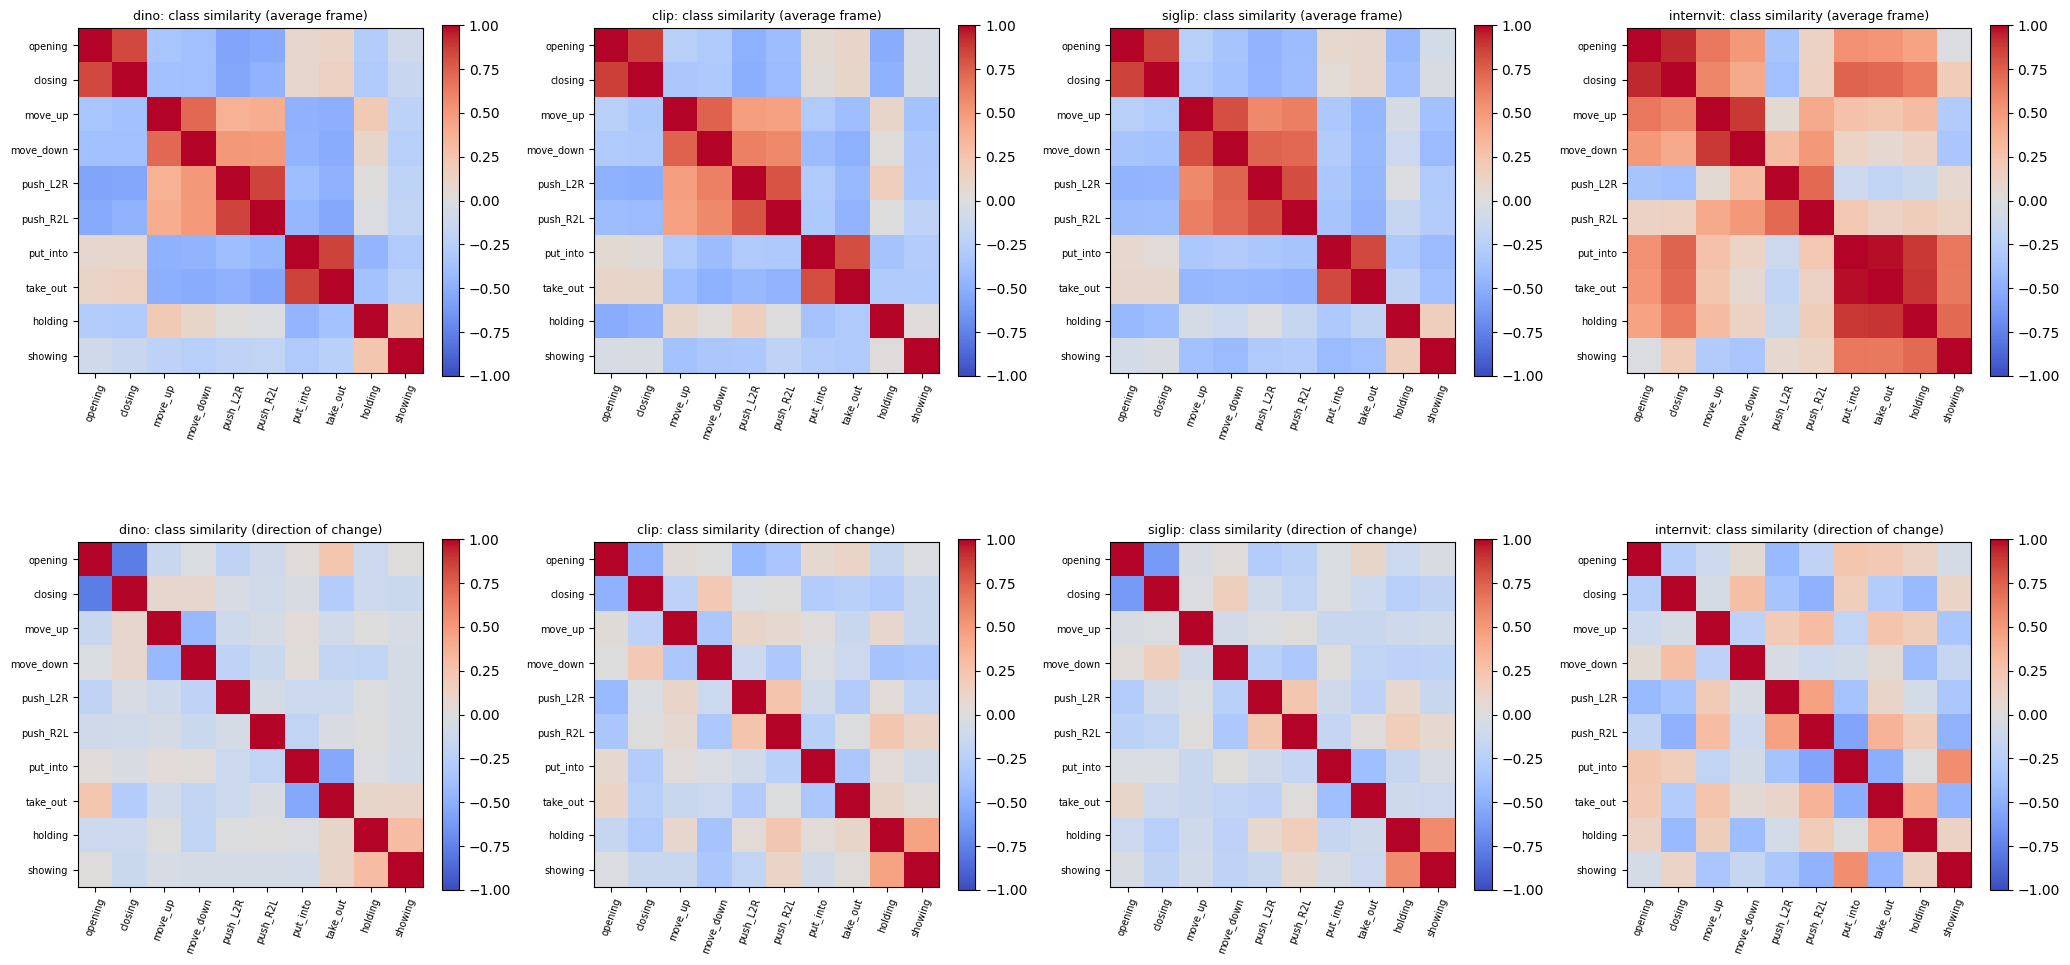

  encoder  avg_frame_sim_reversal_partners  avg_frame_sim_other_classes  change_dir_sim_reversal_partners  change_dir_sim_other_classes
     dino                            0.813                       -0.218                            -0.451                        -0.069
     clip                            0.802                       -0.154                            -0.222                        -0.095
   siglip                            0.829                       -0.130                            -0.212                        -0.092
internvit                            0.878                        0.258                            -0.132                        -0.045

Reversal partners = opening/closing, up/down, left-right, into/out-of.
avg-frame similarity of partners HIGH -> averaging frames cannot separate a clip from its time-reversed twin.
change-direction similarity of partners NEGATIVE (below other classes) -> the direction of change carries the arrow of time.


In [22]:
fig, axes = plt.subplots(2, len(ENCODERS), figsize=(5.2 * len(ENCODERS), 10.5), squeeze=False); rows = []; ii = {c: i for i, c in enumerate(SHORT)}
for col, k in enumerate(ENCODERS):
    En = EN[k]
    pooled = En.mean(1); pooled_c = unit(pooled - pooled.mean(0))            # one vector per clip: its average frame, centered by the global mean
    delta = En[:, -1] - En[:, 0]; delta_c = unit(delta - delta.mean(0))      # one vector per clip: how it changed from start to end, centered the same way
    cent = unit(np.stack([pooled_c[lab == c].mean(0) for c in SHORT])); dirs = unit(np.stack([delta_c[lab == c].mean(0) for c in SHORT]))
    Mc, Md = cent @ cent.T, dirs @ dirs.T                                    # 10x10 class-to-class cosine similarity
    for r, (M, title, vmin) in enumerate([(Mc, "class similarity (average frame)", -1), (Md, "class similarity (direction of change)", -1)]):
        a = axes[r, col]; im = a.imshow(M, cmap="coolwarm", vmin=vmin, vmax=1); a.set_xticks(range(10)); a.set_yticks(range(10))
        a.set_xticklabels(SHORT, rotation=70, fontsize=7); a.set_yticklabels(SHORT, fontsize=7); a.set_title(f"{k}: {title}", fontsize=9); plt.colorbar(im, ax=a, fraction=0.046)
    nonp = [(i, j) for i in range(8) for j in range(8) if i != j and SHORT[j] != PARTNER_NAME[SHORT[i]]]
    rows.append(dict(encoder=k, avg_frame_sim_reversal_partners=np.mean([Mc[ii[a_], ii[b_]] for a_, b_ in PAIRS]), avg_frame_sim_other_classes=np.mean([Mc[i, j] for i, j in nonp]),
                     change_dir_sim_reversal_partners=np.mean([Md[ii[a_], ii[b_]] for a_, b_ in PAIRS]), change_dir_sim_other_classes=np.mean([Md[i, j] for i, j in nonp])))
plt.tight_layout(); plt.savefig(f"{OUT}/fig_sequence_similarity.png", dpi=140); plt.show()
summ = pd.DataFrame(rows).round(3); print(summ.to_string(index=False)); summ.to_csv(f"{OUT}/sequence_similarity_summary.csv", index=False)
print("\nReversal partners = opening/closing, up/down, left-right, into/out-of.")
print("avg-frame similarity of partners HIGH -> averaging frames cannot separate a clip from its time-reversed twin.")
print("change-direction similarity of partners NEGATIVE (below other classes) -> the direction of change carries the arrow of time.")

dino: variance explained by the 2 plotted directions: [0.026 0.016]
clip: variance explained by the 2 plotted directions: [0.061 0.047]
siglip: variance explained by the 2 plotted directions: [0.045 0.043]
internvit: variance explained by the 2 plotted directions: [0.651 0.096]


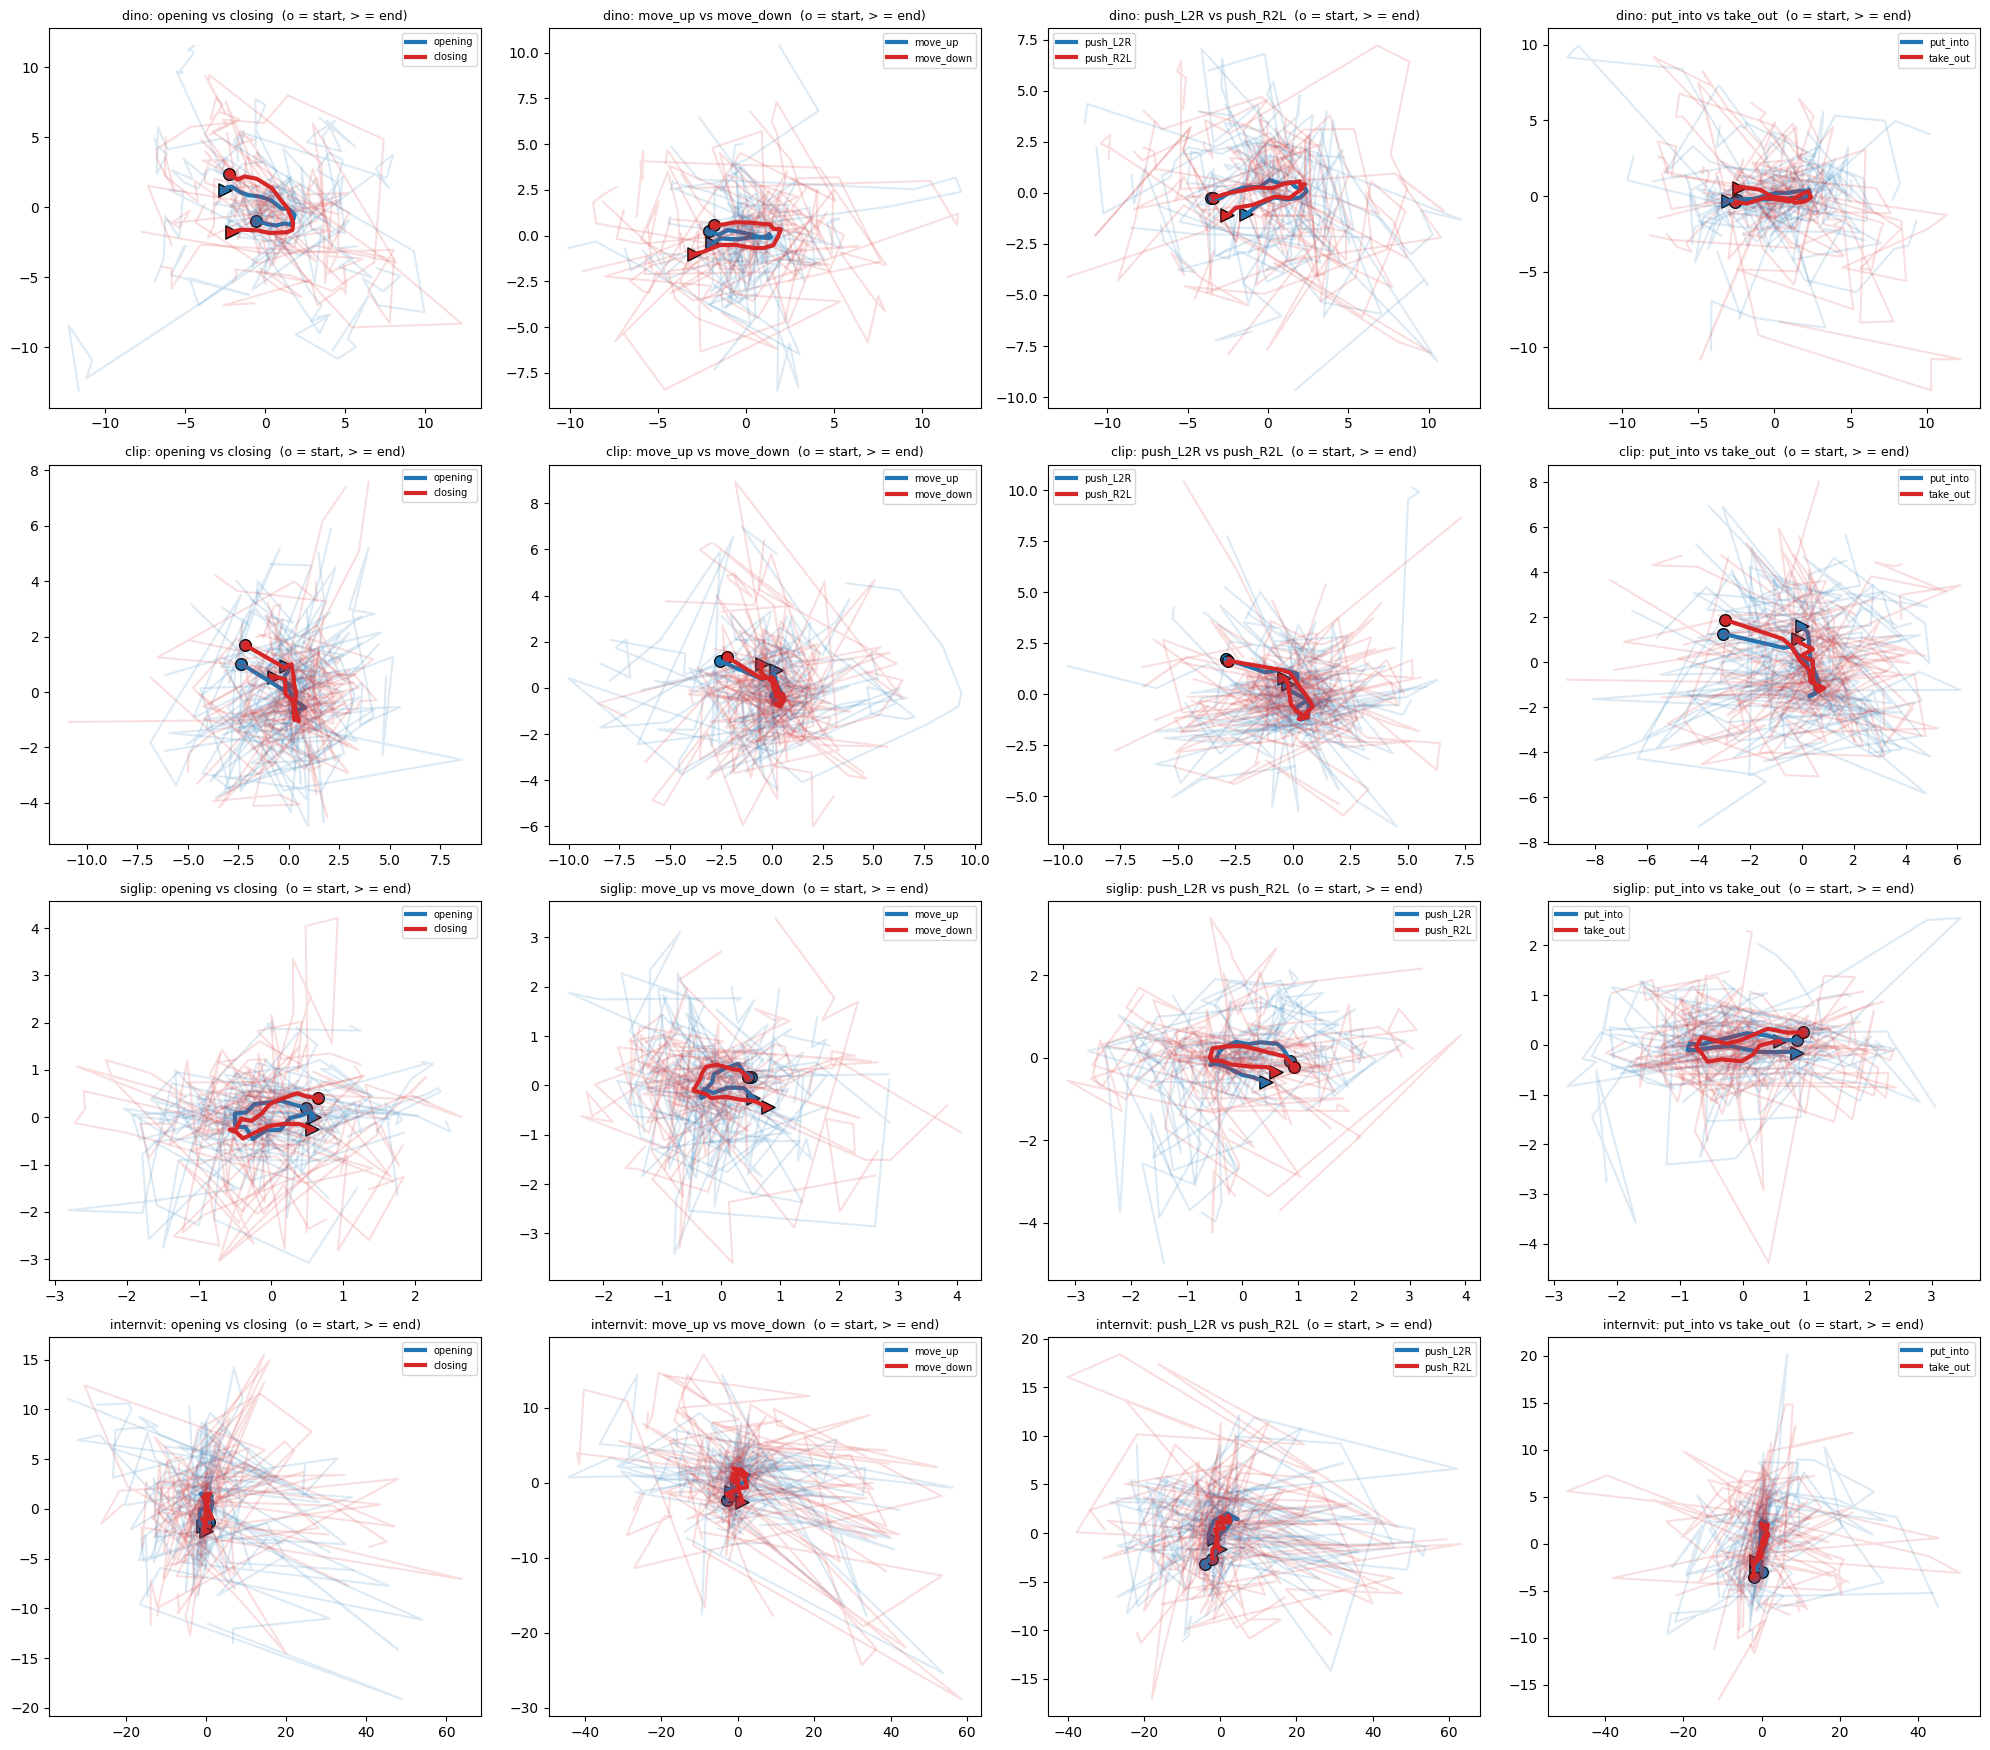

In [24]:
from sklearn.decomposition import PCA
fig, axes = plt.subplots(len(ENCODERS), 4, figsize=(20, 4.4 * len(ENCODERS)), squeeze=False)
for r, k in enumerate(ENCODERS):
    E = EMB[k]; Ec = E - E.mean(1, keepdims=True); flat = Ec.reshape(-1, E.shape[-1])           # remove each clip's own mean -> only within-clip change remains
    pca = PCA(2, random_state=SEED).fit(flat[rng.choice(len(flat), 20000, replace=False)]); Z = pca.transform(flat).reshape(len(E), T, 2)
    print(f"{k}: variance explained by the 2 plotted directions: {pca.explained_variance_ratio_.round(3)}")
    for a, (c1, c2) in zip(axes[r], PAIRS):
        for c, col in [(c1, "tab:blue"), (c2, "tab:red")]:
            zs = Z[lab == c]
            for z in zs[rng.choice(len(zs), 15, replace=False)]: a.plot(z[:, 0], z[:, 1], color=col, alpha=0.15)           # 15 individual clips
            m = zs.mean(0); a.plot(m[:, 0], m[:, 1], color=col, lw=3, label=c)                                            # class mean path
            a.scatter(*m[0], color=col, marker="o", s=70, edgecolor="k"); a.scatter(*m[-1], color=col, marker=">", s=90, edgecolor="k")
        a.set_title(f"{k}: {c1} vs {c2}  (o = start, > = end)", fontsize=9); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_trajectories_pca.png", dpi=130); plt.show()

  encoder               summary  within_class  between_class   gap
     dino single frame (middle)         0.022         -0.001 0.023
     dino             mean pool         0.024         -0.003 0.027
     dino              max pool         0.400          0.376 0.024
     clip single frame (middle)         0.028          0.001 0.027
     clip             mean pool         0.028         -0.003 0.031
     clip              max pool         0.476          0.453 0.023
   siglip single frame (middle)         0.028          0.001 0.028
   siglip             mean pool         0.030         -0.003 0.033
   siglip              max pool         0.455          0.433 0.023
internvit single frame (middle)         0.088          0.048 0.040
internvit             mean pool         0.110          0.068 0.042
internvit              max pool         0.558          0.528 0.030

   encoder  pooled_vs_pooled_reversed  first_vs_last_frame
     dino                        1.0                0.665
     clip  

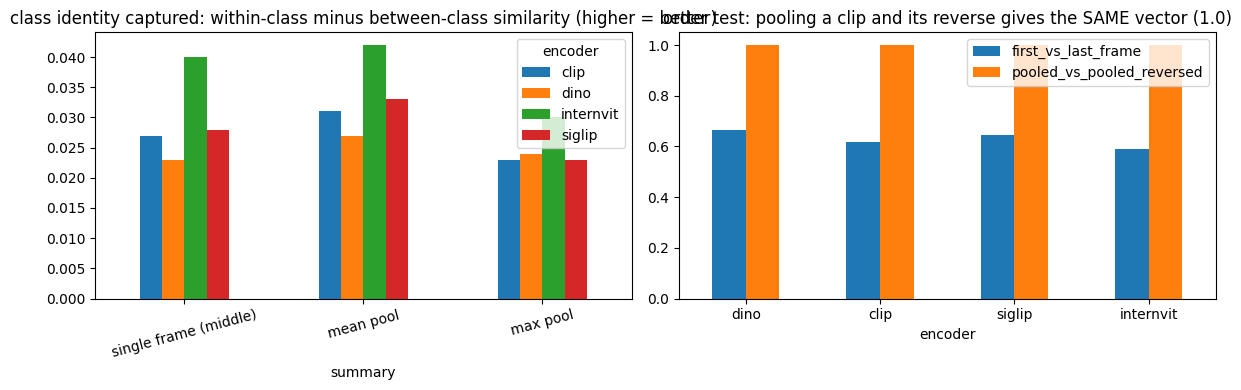

In [25]:
prow, orow = [], []
for k in ENCODERS:
    E = EMB[k]; Ec = unit(E - E.reshape(-1, E.shape[-1]).mean(0))        # center by the global mean frame embedding (label-free), then length 1
    variants = {"single frame (middle)": Ec[:, T // 2], "mean pool": unit(Ec.mean(1)), "max pool": unit(Ec.max(1))}
    same = lab[:, None] == lab[None, :]; off = ~np.eye(len(lab), dtype=bool)
    for name, X_ in variants.items():
        S = X_ @ X_.T                                                     # clip-to-clip cosine similarity
        prow.append(dict(encoder=k, summary=name, within_class=S[same & off].mean(), between_class=S[~same].mean(), gap=S[same & off].mean() - S[~same].mean()))
    pf, pr = unit(Ec.mean(1)), unit(Ec[:, ::-1].mean(1))                 # pooled clip vs pooled REVERSED clip
    orow.append(dict(encoder=k, pooled_vs_pooled_reversed=(pf * pr).sum(1).mean(), first_vs_last_frame=(Ec[:, 0] * Ec[:, -1]).sum(1).mean()))
pool = pd.DataFrame(prow).round(3); print(pool.to_string(index=False)); order = pd.DataFrame(orow).round(3); print("\n", order.to_string(index=False))
pool.to_csv(f"{OUT}/pooling_summary.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pool.pivot(index="summary", columns="encoder", values="gap").loc[["single frame (middle)", "mean pool", "max pool"]].plot.bar(ax=ax[0], rot=15)
ax[0].set_title("class identity captured: within-class minus between-class similarity (higher = better)")
order.set_index("encoder")[["first_vs_last_frame", "pooled_vs_pooled_reversed"]].plot.bar(ax=ax[1], rot=0)
ax[1].set_title("order test: pooling a clip and its reverse gives the SAME vector (1.0)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_temporal_pooling.png", dpi=150); plt.show()

In [26]:
subprocess.run(f"mkdir -p {BACKUP} && cp -rn {CACHE} {OUT} {BACKUP}/", shell=True); print("backed up to", BACKUP)

backed up to /content/drive/MyDrive/ssv2_out


Single VS Temporal Models

In [28]:
import os, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt

CACHE, OUT, dev = "/content/cache", "/content/results", "cuda"
SEEDS, EPOCHS, BS, LR, WD, D_MODEL = [0, 1, 2], 40, 64, 1e-3, 0.05, 128    # fixed a priori; use [0,1,2,3,4] for the final run
SHORT = ["opening","closing","move_up","move_down","push_L2R","push_R2L","put_into","take_out","holding","showing"]
partner = np.array([1, 0, 3, 2, 5, 4, 7, 6, -1, -1])

df = pd.read_csv(f"{OUT}/dataset_index.csv"); V = df[df.valid]; vidx = V.index.values
y = V.cls.map({c: i for i, c in enumerate(SHORT)}).values
is_tr = V.split.values == "train"; tri, tei = np.where(is_tr)[0], np.where(~is_tr)[0]   # 'val' split = test set
ytr, yn = y[tri], y[tei]; pair_m = yn < 8
yt_tr = torch.as_tensor(ytr, device=dev)
ENCODERS = [k for k in ["dino", "clip", "siglip"] if os.path.exists(f"{CACHE}/{k}_cls.npy") and os.path.exists(f"{CACHE}/{k}_grid2x2.npy")]
print("encoders:", ENCODERS, "| train:", len(tri), "| test:", len(tei))

def load_feats(k):        # per frame: global embedding + 2x2 patch grid, standardised with TRAIN statistics only -> [clips, 16, D]
    cls = np.load(f"{CACHE}/{k}_cls.npy")[vidx].astype(np.float32)
    gr = np.load(f"{CACHE}/{k}_grid2x2.npy")[vidx].astype(np.float32); gr = gr.reshape(len(vidx), gr.shape[1], -1)
    Fm = np.concatenate([cls, gr], -1); flat = Fm[tri].reshape(-1, Fm.shape[-1])
    return ((Fm - flat.mean(0)) / (flat.std(0) + 1e-6)).astype(np.float32)

def reorder(X, order, seed=0):          # X [n,T,D] numpy
    if order == "shuffled": rs = np.random.RandomState(seed); return np.stack([x[rs.permutation(len(x))] for x in X])
    if order == "reversed": return X[:, ::-1]
    return X

def metrics(Po, Ps, Pr):                # each [seeds, n] (or [n]) of predicted labels on the test clips
    Po, Ps, Pr = [np.atleast_2d(a) for a in (Po, Ps, Pr)]
    ok = (Po == yn) & pair_m
    return dict(ordered=(Po == yn).mean(1), shuffled=(Ps == yn).mean(1), reversed=(Pr == yn).mean(1),
                flip=((Pr == partner[yn]) & ok).sum(1) / np.maximum(ok.sum(1), 1),
                acc_pair=(Po[:, pair_m] == yn[pair_m]).mean(1), acc_static=(Po[:, ~pair_m] == yn[~pair_m]).mean(1))
ms = lambda a: f"{np.mean(a):.3f}±{np.std(a):.3f}" if len(np.atleast_1d(a)) > 1 else f"{float(np.mean(a)):.3f}"
ROWS, CORR = [], {}                      # CORR: per-clip correctness (seed-averaged) for paired bootstrap
def log(tier, enc, model, params, m):
    ROWS.append(dict(tier=tier, encoder=enc, model=model, params=params, **{k: ms(v) for k, v in m.items()}))
    print(f"{tier} | {enc:7s} | {model:28s} ordered {ms(m['ordered'])}  shuffled {ms(m['shuffled'])}  reversed {ms(m['reversed'])}")

encoders: ['dino', 'clip', 'siglip'] | train: 1490 | test: 400


In [29]:
def proto_feat(X, kind):
    if kind == "single": return X[:, X.shape[1] // 2]
    m = X.mean(1)
    if kind == "mean": return m
    return np.concatenate([m, X[:, -5:].mean(1) - X[:, :5].mean(1)], 1)       # "temporal": average frame + direction of change

def unit(a): return a / (np.linalg.norm(a, axis=-1, keepdims=True) + 1e-8)

for k in ENCODERS:
    X = load_feats(k); Xtr, Xte = X[tri], X[tei]
    for kind, name in [("single", "proto_single_frame"), ("mean", "proto_mean_pool"), ("temporal", "proto_temporal(mean+delta)")]:
        if kind == "single":                                                    # prototypes from ALL train frames (more data for the baseline)
            Ftr = Xtr.reshape(-1, Xtr.shape[-1]); Ltr = np.repeat(ytr, Xtr.shape[1])
        else: Ftr, Ltr = proto_feat(Xtr, kind), ytr
        mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-6
        P_ = unit(np.stack([((Ftr - mu) / sd)[Ltr == c].mean(0) for c in range(10)]))     # one prototype per class
        pred = lambda order: (unit((proto_feat(reorder(Xte, order), kind) - mu) / sd) @ P_.T).argmax(1)
        Po, Ps, Pr = pred("ordered"), pred("shuffled"), pred("reversed")
        log("B prototype", k, name, 0, metrics(Po, Ps, Pr)); CORR[(k, name, "ordered")] = (Po == yn).astype(float)

B prototype | dino    | proto_single_frame           ordered 0.300  shuffled 0.280  reversed 0.318
B prototype | dino    | proto_mean_pool              ordered 0.307  shuffled 0.307  reversed 0.307
B prototype | dino    | proto_temporal(mean+delta)   ordered 0.545  shuffled 0.300  reversed 0.128
B prototype | clip    | proto_single_frame           ordered 0.282  shuffled 0.240  reversed 0.280
B prototype | clip    | proto_mean_pool              ordered 0.268  shuffled 0.268  reversed 0.268
B prototype | clip    | proto_temporal(mean+delta)   ordered 0.465  shuffled 0.282  reversed 0.165
B prototype | siglip  | proto_single_frame           ordered 0.312  shuffled 0.268  reversed 0.312
B prototype | siglip  | proto_mean_pool              ordered 0.300  shuffled 0.300  reversed 0.300
B prototype | siglip  | proto_temporal(mean+delta)   ordered 0.492  shuffled 0.302  reversed 0.163


In [30]:
class SingleFrame(nn.Module):           # BASELINE: one frame -> MLP (random frame in training, middle frame at test)
    def __init__(s, D, H=256, C=10, p=0.3):
        super().__init__(); s.net = nn.Sequential(nn.Dropout(p), nn.Linear(D, H), nn.GELU(), nn.Dropout(p), nn.Linear(H, C))
    def forward(s, x):
        if s.training: return s.net(x[torch.arange(len(x), device=x.device), torch.randint(0, x.shape[1], (len(x),), device=x.device)])
        return s.net(x[:, x.shape[1] // 2])
class MeanPool(nn.Module):              # CONTROL: all frames, no order
    def __init__(s, D, H=256, C=10, p=0.3):
        super().__init__(); s.net = nn.Sequential(nn.Dropout(p), nn.Linear(D, H), nn.GELU(), nn.Dropout(p), nn.Linear(H, C))
    def forward(s, x): return s.net(x.mean(1))
class GRUNet(nn.Module):                # TEMPORAL: recurrent
    def __init__(s, D, d=D_MODEL, C=10, p=0.2):
        super().__init__(); s.proj = nn.Sequential(nn.Dropout(p), nn.Linear(D, d), nn.GELU())
        s.gru = nn.GRU(d, d, batch_first=True); s.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(p), nn.Linear(d, C))
    def forward(s, x): _, h = s.gru(s.proj(x)); return s.head(h[-1])
class TCN(nn.Module):                   # TEMPORAL: two 1-D convolutions over time (kernel 3, dilation 1 then 2)
    def __init__(s, D, d=D_MODEL, C=10, p=0.2):
        super().__init__(); s.proj = nn.Sequential(nn.Dropout(p), nn.Linear(D, d))
        s.c1 = nn.Conv1d(d, d, 3, padding=1); s.c2 = nn.Conv1d(d, d, 3, padding=2, dilation=2)
        s.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(p), nn.Linear(d, C))
    def forward(s, x): h = s.proj(x).transpose(1, 2); h = F.gelu(s.c1(h)); h = F.gelu(s.c2(h)); return s.head(h.mean(2))
class TemporalTransformer(nn.Module):   # TEMPORAL: 2-layer encoder, learned positions, [CLS] token
    def __init__(s, D, T_=16, d=D_MODEL, L=2, heads=4, C=10, p=0.2):
        super().__init__(); s.proj = nn.Sequential(nn.Dropout(p), nn.Linear(D, d))
        s.pos = nn.Parameter(torch.randn(1, T_, d) * 0.02); s.cls = nn.Parameter(torch.zeros(1, 1, d))
        s.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 2 * d, p, activation="gelu", batch_first=True, norm_first=True), L, enable_nested_tensor=False)
        s.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, C))
    def forward(s, x): return s.head(s.enc(torch.cat([s.cls.expand(len(x), -1, -1), s.proj(x) + s.pos[:, :x.shape[1]]], 1))[:, 0])
class DeltaTransformer(TemporalTransformer):   # TEMPORAL: tokens = [frame, frame - previous frame]
    def __init__(s, D, **kw): super().__init__(2 * D, **kw)
    def forward(s, x): return super().forward(torch.cat([x, torch.cat([torch.zeros_like(x[:, :1]), x[:, 1:] - x[:, :-1]], 1)], -1))

# name -> (class, train on shuffled frame order?)
MODELS = {"single_frame": (SingleFrame, False), "mean_pool": (MeanPool, False),
          "gru": (GRUNet, False), "tcn": (TCN, False), "transformer": (TemporalTransformer, False), "delta_transformer": (DeltaTransformer, False),
          "gru_shuftrain": (GRUNet, True), "tcn_shuftrain": (TCN, True), "transformer_shuftrain": (TemporalTransformer, True), "delta_transformer_shuftrain": (DeltaTransformer, True)}

def tshuffle(xb): p = torch.rand(xb.shape[:2], device=xb.device).argsort(1); return xb.gather(1, p[..., None].expand(-1, -1, xb.shape[-1]))

def fit(cls, shuf, Xtr, seed):
    torch.manual_seed(seed); model = cls(Xtr.shape[-1]).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD); nb = (len(Xtr) + BS - 1) // BS
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * nb, pct_start=0.1)
    for _ in range(EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr), device=dev)
        for s in range(0, len(Xtr), BS):
            i = perm[s:s + BS]; xb = tshuffle(Xtr[i]) if shuf else Xtr[i]
            loss = F.cross_entropy(model(xb), yt_tr[i], label_smoothing=0.1)
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    return model.eval()

@torch.no_grad()
def predict(model, X, order):                       # X torch [n,T,D]
    out = []
    for s in range(0, len(X), 256):
        xb = X[s:s + 256]
        if order == "shuffled": xb = tshuffle(xb)
        if order == "reversed": xb = xb.flip(1)
        out.append(model(xb).argmax(1))
    return torch.cat(out).cpu().numpy()

TRAINED = {}
for k in ENCODERS:
    X = torch.tensor(load_feats(k), device=dev); Xtr, Xte = X[torch.as_tensor(tri, device=dev)], X[torch.as_tensor(tei, device=dev)]
    for name, (cls, shuf) in MODELS.items():
        ms_ = [fit(cls, shuf, Xtr, s) for s in SEEDS]; TRAINED[(k, name)] = ms_
        torch.manual_seed(1234)
        P = {o: np.stack([predict(m, Xte, o) for m in ms_]) for o in ["ordered", "shuffled", "reversed"]}
        log("C trained", k, name, sum(p.numel() for p in ms_[0].parameters()), metrics(P["ordered"], P["shuffled"], P["reversed"]))
        for o in P: CORR[(k, name, o)] = (P[o] == yn).mean(0)

# ---------- one combined table (+ Tier A zero-shot from the previous cell, if it was run)
res = pd.DataFrame(ROWS)
if os.path.exists(f"{OUT}/section4_zeroshot.csv"):
    z = pd.read_csv(f"{OUT}/section4_zeroshot.csv"); z = z[z.eval_set == "test"]
    za = pd.DataFrame(dict(tier="A zero-shot", encoder=z.encoder, model=z.method + np.where(z.calibrated, " (calibrated)", " (raw)"), params=0,
                           ordered=z.ordered, shuffled=z.shuffled, reversed=z.reversed, flip=z.flip_rate, acc_pair=z.acc_pair, acc_static=z.acc_static))
    res = pd.concat([za, res], ignore_index=True)
pd.set_option("display.width", 250); print("\n== SECTION 4: all tiers (test clips, chance 0.10) =="); print(res.to_string(index=False))
res.to_csv(f"{OUT}/section4_all_tiers.csv", index=False)

C trained | dino    | single_frame                 ordered 0.307±0.011  shuffled 0.301±0.015  reversed 0.311±0.017
C trained | dino    | mean_pool                    ordered 0.368±0.003  shuffled 0.368±0.003  reversed 0.368±0.003
C trained | dino    | gru                          ordered 0.452±0.011  shuffled 0.294±0.014  reversed 0.180±0.002
C trained | dino    | tcn                          ordered 0.427±0.007  shuffled 0.360±0.009  reversed 0.301±0.023
C trained | dino    | transformer                  ordered 0.431±0.001  shuffled 0.422±0.002  reversed 0.415±0.007
C trained | dino    | delta_transformer            ordered 0.542±0.018  shuffled 0.423±0.018  reversed 0.279±0.004
C trained | dino    | gru_shuftrain                ordered 0.361±0.001  shuffled 0.367±0.004  reversed 0.355±0.000
C trained | dino    | tcn_shuftrain                ordered 0.358±0.002  shuffled 0.353±0.012  reversed 0.359±0.007
C trained | dino    | transformer_shuftrain        ordered 0.413±0.003  shuffled


== paired bootstrap (difference in accuracy) ==

[dino]
  temporal vs single frame: delta_transformer - single_frame: +0.234 [+0.194, +0.274]
  order vs more frames:  delta_transformer - mean_pool: +0.173 [+0.135, +0.211]
  uses order? delta_transformer(ordered) - its shuffle-trained twin (shuffled test): +0.049 [+0.018, +0.081]
  uses order? transformer(ordered) - its shuffle-trained twin (shuffled test): +0.018 [-0.004, +0.040]
  uses order? gru(ordered) - its shuffle-trained twin (shuffled test): +0.086 [+0.046, +0.126]
  uses order? tcn(ordered) - its shuffle-trained twin (shuffled test): +0.074 [+0.045, +0.102]

[clip]
  temporal vs single frame: delta_transformer - single_frame: +0.157 [+0.118, +0.194]
  order vs more frames:  delta_transformer - mean_pool: +0.131 [+0.098, +0.162]
  uses order? delta_transformer(ordered) - its shuffle-trained twin (shuffled test): +0.018 [-0.016, +0.049]
  uses order? transformer(ordered) - its shuffle-trained twin (shuffled test): -0.008 [-0.02

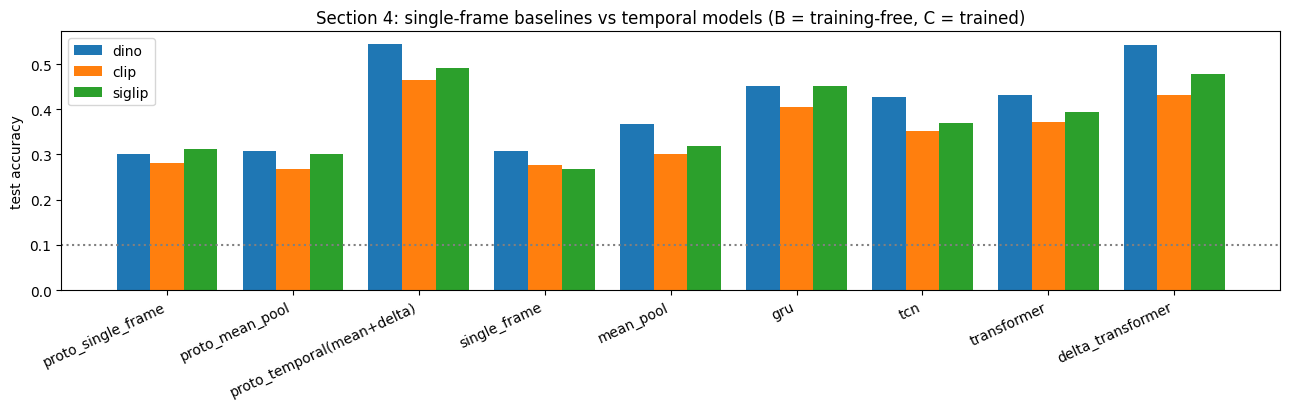

In [31]:
def boot(a, b, n=2000):                             # paired bootstrap over test clips
    d = CORR[a] - CORR[b]; rs = np.random.RandomState(0); bs = [d[rs.randint(0, len(d), len(d))].mean() for _ in range(n)]
    return f"{d.mean():+.3f} [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]"
print("\n== paired bootstrap (difference in accuracy) ==")
for k in ENCODERS:
    print(f"\n[{k}]")
    for nm, a, b in [("temporal vs single frame: delta_transformer - single_frame", (k, "delta_transformer", "ordered"), (k, "single_frame", "ordered")),
                     ("order vs more frames:  delta_transformer - mean_pool", (k, "delta_transformer", "ordered"), (k, "mean_pool", "ordered")),
                     ("uses order? delta_transformer(ordered) - its shuffle-trained twin (shuffled test)", (k, "delta_transformer", "ordered"), (k, "delta_transformer_shuftrain", "shuffled")),
                     ("uses order? transformer(ordered) - its shuffle-trained twin (shuffled test)", (k, "transformer", "ordered"), (k, "transformer_shuftrain", "shuffled")),
                     ("uses order? gru(ordered) - its shuffle-trained twin (shuffled test)", (k, "gru", "ordered"), (k, "gru_shuftrain", "shuffled")),
                     ("uses order? tcn(ordered) - its shuffle-trained twin (shuffled test)", (k, "tcn", "ordered"), (k, "tcn_shuftrain", "shuffled"))]:
        print(f"  {nm}: {boot(a, b)}")

main = ["proto_single_frame", "proto_mean_pool", "proto_temporal(mean+delta)", "single_frame", "mean_pool", "gru", "tcn", "transformer", "delta_transformer"]
fig, ax = plt.subplots(figsize=(13, 4.2)); w = 0.8 / len(ENCODERS)
for j, k in enumerate(ENCODERS):
    v = [float(str(res[(res.encoder == k) & (res.model == m)].ordered.iloc[0]).split("±")[0]) for m in main]
    ax.bar(np.arange(len(main)) + w * (j - (len(ENCODERS) - 1) / 2), v, w, label=k)
ax.set_xticks(range(len(main))); ax.set_xticklabels(main, rotation=25, ha="right"); ax.axhline(0.1, color="gray", ls=":"); ax.set_ylabel("test accuracy"); ax.legend()
plt.title("Section 4: single-frame baselines vs temporal models (B = training-free, C = trained)"); plt.tight_layout(); plt.savefig(f"{OUT}/fig_section4_all.png", dpi=150); plt.show()

sanity (must match Section 4 'ordered'): {'single_frame': np.float64(0.307), 'mean_pool': np.float64(0.368), 'gru': np.float64(0.452), 'tcn': np.float64(0.427), 'transformer': np.float64(0.431), 'delta_transformer': np.float64(0.542)}


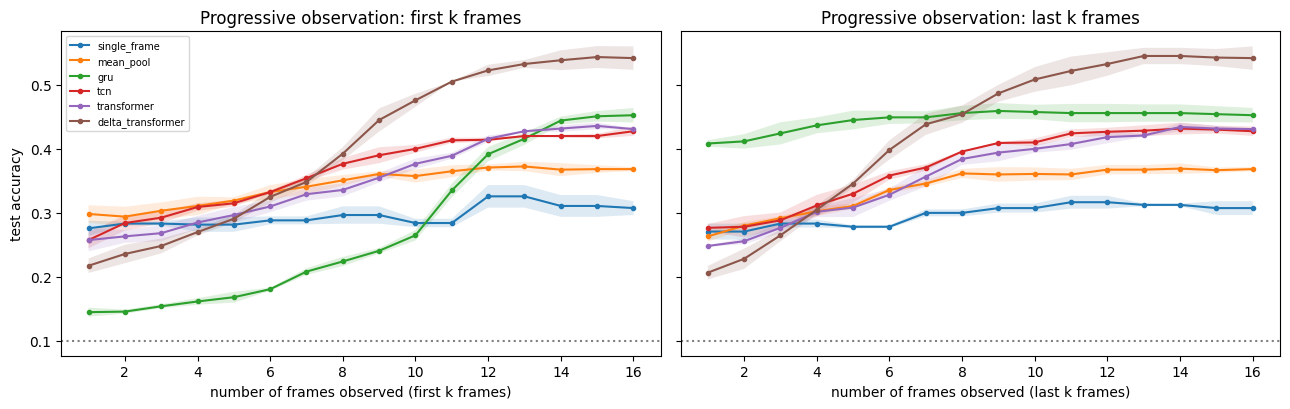

         single_frame mean_pool    gru    tcn transformer delta_transformer
first 1         0.276     0.298  0.145  0.257       0.257             0.217
first 2         0.283     0.294  0.146  0.284       0.263             0.236
first 4         0.282     0.311  0.162  0.309       0.285             0.270
first 8         0.297     0.351  0.224  0.377       0.336             0.392
first 12        0.326     0.371  0.392  0.414       0.416             0.522
first 16        0.307     0.368  0.452  0.427       0.431             0.542
last 1          0.271     0.263  0.408  0.277       0.248             0.207
last 2          0.271     0.280  0.412  0.278       0.256             0.228
last 4          0.283     0.302  0.437  0.312       0.302             0.305
last 8          0.300     0.362  0.456  0.396       0.384             0.454
last 12         0.317     0.367  0.456  0.427       0.418             0.532
last 16         0.307     0.368  0.452  0.427       0.431             0.542


In [32]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt, os
ENC = "dino"; NAMES5 = ["single_frame", "mean_pool", "gru", "tcn", "transformer", "delta_transformer"]
X = torch.tensor(load_feats(ENC), device=dev); T = X.shape[1]
Xtr, Xte = X[torch.as_tensor(tri, device=dev)], X[torch.as_tensor(tei, device=dev)]
yte_t = torch.as_tensor(yn, device=dev); pair_t = torch.as_tensor(pair_m, device=dev)

path = f"{CACHE}/section5_models_{ENC}.pt"; FINAL = {}
if os.path.exists(path):
    sd = torch.load(path)
    for n in NAMES5:
        FINAL[n] = []
        for s in sd[n]: m = MODELS[n][0](Xtr.shape[-1]).to(dev); m.load_state_dict(s); FINAL[n].append(m.eval())
else:
    for n in NAMES5: FINAL[n] = [fit(MODELS[n][0], False, Xtr, s) for s in SEEDS]      # same recipe as Section 4
    torch.save({n: [m.state_dict() for m in v] for n, v in FINAL.items()}, path)

@torch.no_grad()
def eval_models(Xe):                      # Xe [n, m, D]: any number m of frames; returns {model: (acc per seed, pair-class acc per seed)}
    out = {}
    for n, ms_ in FINAL.items():
        a, ap = [], []
        for m in ms_:
            p = torch.cat([m(Xe[s:s + 256]).argmax(1) for s in range(0, len(Xe), 256)])
            a.append((p == yte_t).float().mean().item()); ap.append((p[pair_t] == yte_t[pair_t]).float().mean().item())
        out[n] = (np.array(a), np.array(ap))
    return out

clean = eval_models(Xte); print("sanity (must match Section 4 'ordered'):", {n: round(v[0].mean(), 3) for n, v in clean.items()})

# ---------- Experiment A: progressive observation
first = {k: eval_models(Xte[:, :k]) for k in range(1, T + 1)}       # sees frames 1..k  (early part of the clip)
last  = {k: eval_models(Xte[:, T - k:]) for k in range(1, T + 1)}   # sees frames T-k+1..T (late part of the clip)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a_, (D_, title) in zip(ax, [(first, "first k frames"), (last, "last k frames")]):
    for n in NAMES5:
        mu = np.array([D_[k][n][0].mean() for k in range(1, T + 1)]); sd = np.array([D_[k][n][0].std() for k in range(1, T + 1)])
        a_.plot(range(1, T + 1), mu, marker="o", ms=3, label=n); a_.fill_between(range(1, T + 1), mu - sd, mu + sd, alpha=0.15)
    a_.axhline(0.1, color="gray", ls=":"); a_.set_xlabel(f"number of frames observed ({title})"); a_.set_title(f"Progressive observation: {title}")
ax[0].set_ylabel("test accuracy"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT}/fig_section5_progressive.png", dpi=150); plt.show()
ks = [1, 2, 4, 8, 12, 16]
tab = pd.DataFrame({n: [f"{first[k][n][0].mean():.3f}" for k in ks] for n in NAMES5}, index=[f"first {k}" for k in ks])
tab2 = pd.DataFrame({n: [f"{last[k][n][0].mean():.3f}" for k in ks] for n in NAMES5}, index=[f"last {k}" for k in ks])
print(pd.concat([tab, tab2]).to_string()); pd.concat([tab, tab2]).to_csv(f"{OUT}/section5_progressive.csv")

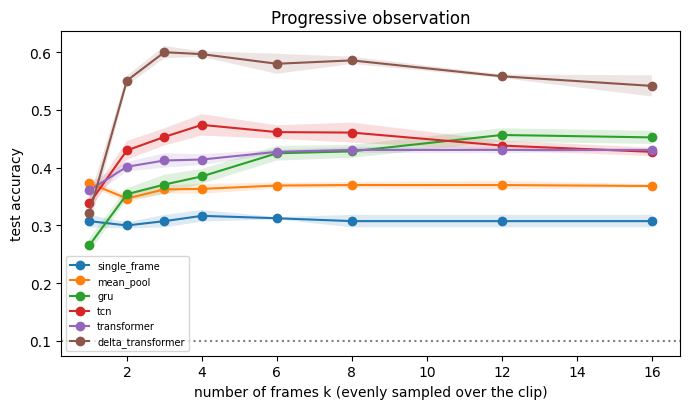

     single_frame mean_pool    gru    tcn transformer delta_transformer
k=1         0.307     0.373  0.266  0.338       0.361             0.322
k=2         0.300     0.347  0.354  0.430       0.402             0.551
k=3         0.307     0.362  0.371  0.453       0.412             0.600
k=4         0.317     0.363  0.385  0.474       0.414             0.597
k=6         0.312     0.369  0.425  0.462       0.427             0.580
k=8         0.307     0.370  0.428  0.461       0.431             0.586
k=12        0.307     0.370  0.457  0.438       0.431             0.558
k=16        0.307     0.368  0.452  0.427       0.431             0.542


In [34]:
def sample_idx(k, T=16):          # k evenly spaced frames across the whole clip, in order
    return np.unique(np.round((np.arange(k) + 0.5) * T / k - 0.5).astype(int))

KS = [1, 2, 3, 4, 6, 8, 12, 16]
prog = {k: eval_models(Xte[:, torch.as_tensor(sample_idx(k, T), device=dev)]) for k in KS}

plt.figure(figsize=(7, 4.2))
for n in NAMES5:
    mu = np.array([prog[k][n][0].mean() for k in KS]); sd = np.array([prog[k][n][0].std() for k in KS])
    plt.plot(KS, mu, marker="o", label=n); plt.fill_between(KS, mu - sd, mu + sd, alpha=0.15)
plt.axhline(0.1, color="gray", ls=":"); plt.xlabel("number of frames k (evenly sampled over the clip)"); plt.ylabel("test accuracy")
plt.title("Progressive observation"); plt.legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT}/fig_section5_progressive.png", dpi=150); plt.show()

tab = pd.DataFrame({n: [f"{prog[k][n][0].mean():.3f}" for k in KS] for n in NAMES5}, index=[f"k={k}" for k in KS])
print(tab.to_string()); tab.to_csv(f"{OUT}/section5_progressive.csv")

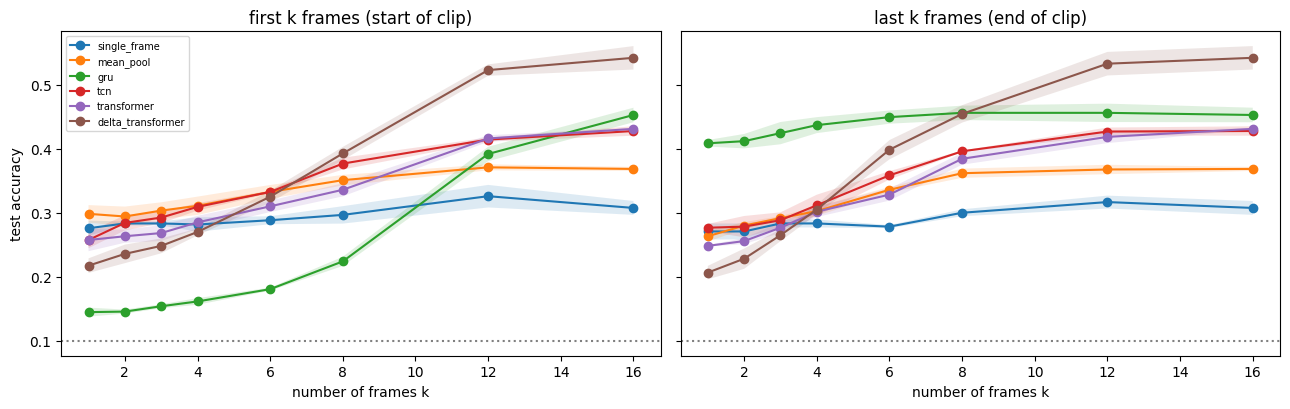

         single_frame mean_pool    gru    tcn transformer delta_transformer
first 1         0.276     0.298  0.145  0.257       0.257             0.217
first 2         0.283     0.294  0.146  0.284       0.263             0.236
first 3         0.283     0.303  0.154  0.292       0.268             0.248
first 4         0.282     0.311  0.162  0.309       0.285             0.270
first 6         0.288     0.333  0.181  0.332       0.310             0.325
first 8         0.297     0.351  0.224  0.377       0.336             0.392
first 12        0.326     0.371  0.392  0.414       0.416             0.522
first 16        0.307     0.368  0.452  0.427       0.431             0.542
last 1          0.271     0.263  0.408  0.277       0.248             0.207
last 2          0.271     0.280  0.412  0.278       0.256             0.228
last 3          0.283     0.292  0.424  0.288       0.277             0.265
last 4          0.283     0.302  0.437  0.312       0.302             0.305
last 6      

In [35]:
KS = [1, 2, 3, 4, 6, 8, 12, 16]
first = {k: eval_models(Xte[:, :k]) for k in KS}          # only the START of the clip: frames 1..k
last  = {k: eval_models(Xte[:, T - k:]) for k in KS}      # only the END of the clip: frames T-k+1..T

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a_, (D_, title) in zip(ax, [(first, "first k frames (start of clip)"), (last, "last k frames (end of clip)")]):
    for n in NAMES5:
        mu = np.array([D_[k][n][0].mean() for k in KS]); sd = np.array([D_[k][n][0].std() for k in KS])
        a_.plot(KS, mu, marker="o", label=n); a_.fill_between(KS, mu - sd, mu + sd, alpha=0.15)
    a_.axhline(0.1, color="gray", ls=":"); a_.set_xlabel("number of frames k"); a_.set_title(title)
ax[0].set_ylabel("test accuracy"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_section5_first_last.png", dpi=150); plt.show()

t_first = pd.DataFrame({n: [f"{first[k][n][0].mean():.3f}" for k in KS] for n in NAMES5}, index=[f"first {k}" for k in KS])
t_last  = pd.DataFrame({n: [f"{last[k][n][0].mean():.3f}" for k in KS] for n in NAMES5}, index=[f"last {k}" for k in KS])
print(pd.concat([t_first, t_last]).to_string()); pd.concat([t_first, t_last]).to_csv(f"{OUT}/section5_first_last.csv")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

done: blur (all frames)
done: noise (all frames)
done: occlusion (all frames)
done: occlusion (50% of frames)
== accuracy under corruption (DINOv2, 3 seeds) ==
                            single_frame    mean_pool          gru          tcn  transformer delta_transformer
clean                        0.307±0.011  0.368±0.003  0.452±0.011  0.427±0.007  0.431±0.001       0.542±0.018
blur (all frames)            0.227±0.017  0.259±0.012  0.292±0.005  0.314±0.001  0.284±0.023       0.352±0.002
noise (all frames)           0.242±0.014  0.308±0.016  0.353±0.012  0.344±0.008  0.292±0.016       0.348±0.011
occlusion (all frames)       0.277±0.005  0.340±0.013  0.390±0.012  0.380±0.010  0.375±0.018       0.404±0.015
occlusion (50% of frames)    0.275±0.018  0.362±0.002  0.435±0.013  0.414±0.006  0.407±0.010       0.456±0.026
drop 50% of frames (8 kept)  0.305±0.005  0.357±0.008  0.428±0.005  0.457±0.011  0.421±0.013       0.564±0.016
drop 75% of frames (4 kept)  0.309±0.004  0.352±0.012  0.342±0.

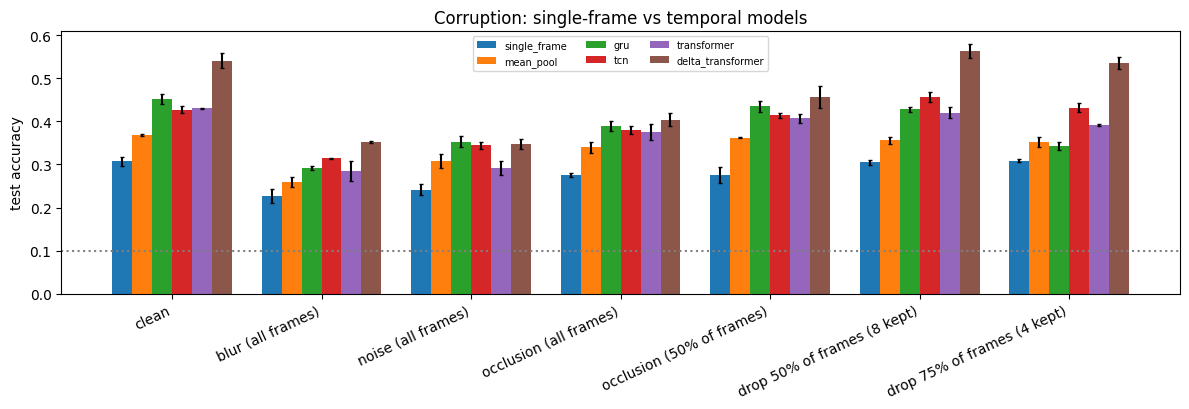

In [37]:
import torch.nn.functional as F, torchvision.transforms.functional as TF
from transformers import AutoModel
dino = AutoModel.from_pretrained("facebook/dinov2-base").to(dev).eval().half()
imean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1); istd = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
Xraw = np.load(f"{CACHE}/frames.npy", mmap_mode="r"); trow = vidx[tei]            # raw frames of the test clips
cls_ = np.load(f"{CACHE}/{ENC}_cls.npy")[vidx].astype(np.float32); gr_ = np.load(f"{CACHE}/{ENC}_grid2x2.npy")[vidx].astype(np.float32).reshape(len(vidx), T, -1)
flat = np.concatenate([cls_, gr_], -1)[tri].reshape(-1, cls_.shape[-1] + gr_.shape[-1]); mu_t = torch.tensor(flat.mean(0), device=dev); sd_t = torch.tensor(flat.std(0) + 1e-6, device=dev)
del cls_, gr_, flat

def c_blur(x):  return TF.gaussian_blur(x, kernel_size=25, sigma=6.0)                  # coarse blur: only large shapes survive
def c_noise(x): return (x + 0.2 * torch.randn_like(x)).clamp(0, 1)                      # heavy Gaussian noise
def c_occ(x):                                                                           # gray 112x112 square (25% of the frame) at a random place
    n = x.shape[0]; ys = torch.randint(0, 113, (n,), device=dev); xs = torch.randint(0, 113, (n,), device=dev); r = torch.arange(224, device=dev)
    m = (r[None, :, None] >= ys[:, None, None]) & (r[None, :, None] < ys[:, None, None] + 112) & (r[None, None, :] >= xs[:, None, None]) & (r[None, None, :] < xs[:, None, None] + 112)
    return torch.where(m[:, None], torch.full_like(x, 0.5), x)

@torch.no_grad()
def embed_test(corrupt=None, frac=1.0, seed=0):          # frac = fraction of frames that get corrupted (chosen at random per frame)
    torch.manual_seed(seed); out = []
    for s in range(0, len(trow), 8):
        ids = trow[s:s + 8]; b = len(ids)
        x = torch.from_numpy(np.stack([Xraw[i] for i in ids])).to(dev).reshape(b * T, 224, 224, 3).permute(0, 3, 1, 2).float() / 255
        if corrupt is not None: x = torch.where((torch.rand(b * T, device=dev) < frac)[:, None, None, None], corrupt(x), x)
        h = dino(pixel_values=((x - imean) / istd).half()).last_hidden_state
        g = F.adaptive_avg_pool2d(h[:, 1:].float().reshape(b * T, 16, 16, -1).permute(0, 3, 1, 2), 2).flatten(2).permute(0, 2, 1).reshape(b, T, -1)   # same layout as Section 3
        out.append(torch.cat([h[:, 0].float().reshape(b, T, -1), g], -1))
    return (torch.cat(out) - mu_t) / sd_t

def drop_frames(Xe, m, seed=0):                          # keep m random frames per clip, in their original order (sequence gets shorter)
    g = torch.Generator(device=dev); g.manual_seed(seed)
    idx = torch.rand(len(Xe), T, device=dev, generator=g).topk(m).indices.sort(1).values
    return Xe.gather(1, idx[..., None].expand(-1, -1, Xe.shape[-1]))

R = {"clean": eval_models(Xte)}
for name, fn, fr in [("blur (all frames)", c_blur, 1.0), ("noise (all frames)", c_noise, 1.0), ("occlusion (all frames)", c_occ, 1.0), ("occlusion (50% of frames)", c_occ, 0.5)]:
    R[name] = eval_models(embed_test(fn, fr)); print("done:", name)
R["drop 50% of frames (8 kept)"] = eval_models(drop_frames(Xte, 8)); R["drop 75% of frames (4 kept)"] = eval_models(drop_frames(Xte, 4))

acc = pd.DataFrame({c: {n: f"{R[c][n][0].mean():.3f}±{R[c][n][0].std():.3f}" for n in NAMES5} for c in R}).T
chg = pd.DataFrame({c: {n: R[c][n][0].mean() - R["clean"][n][0].mean() for n in NAMES5} for c in R}).T.round(3)
print("== accuracy under corruption (DINOv2, 3 seeds) =="); print(acc.to_string()); print("\n== change vs clean =="); print(chg.to_string())
acc.to_csv(f"{OUT}/section5_corruption.csv"); chg.to_csv(f"{OUT}/section5_corruption_change.csv")

fig, ax = plt.subplots(figsize=(12, 4.2)); w = 0.8 / len(NAMES5)
for j, n in enumerate(NAMES5):
    ax.bar(np.arange(len(R)) + w * (j - (len(NAMES5) - 1) / 2), [R[c][n][0].mean() for c in R], w, yerr=[R[c][n][0].std() for c in R], capsize=1.5, label=n)
ax.set_xticks(range(len(R))); ax.set_xticklabels(list(R), rotation=25, ha="right"); ax.axhline(0.1, color="gray", ls=":"); ax.set_ylabel("test accuracy"); ax.legend(fontsize=7, ncol=3)
plt.title("Corruption: single-frame vs temporal models"); plt.tight_layout(); plt.savefig(f"{OUT}/fig_section5_corruption.png", dpi=150); plt.show()

clip: 1 | ground truth: opening | opening a jar


/tmp/ipykernel_1857/912515331.py:7: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(np.asarray(Xraw[trow[j]])).to(dev).permute(0, 3, 1, 2).float() / 255


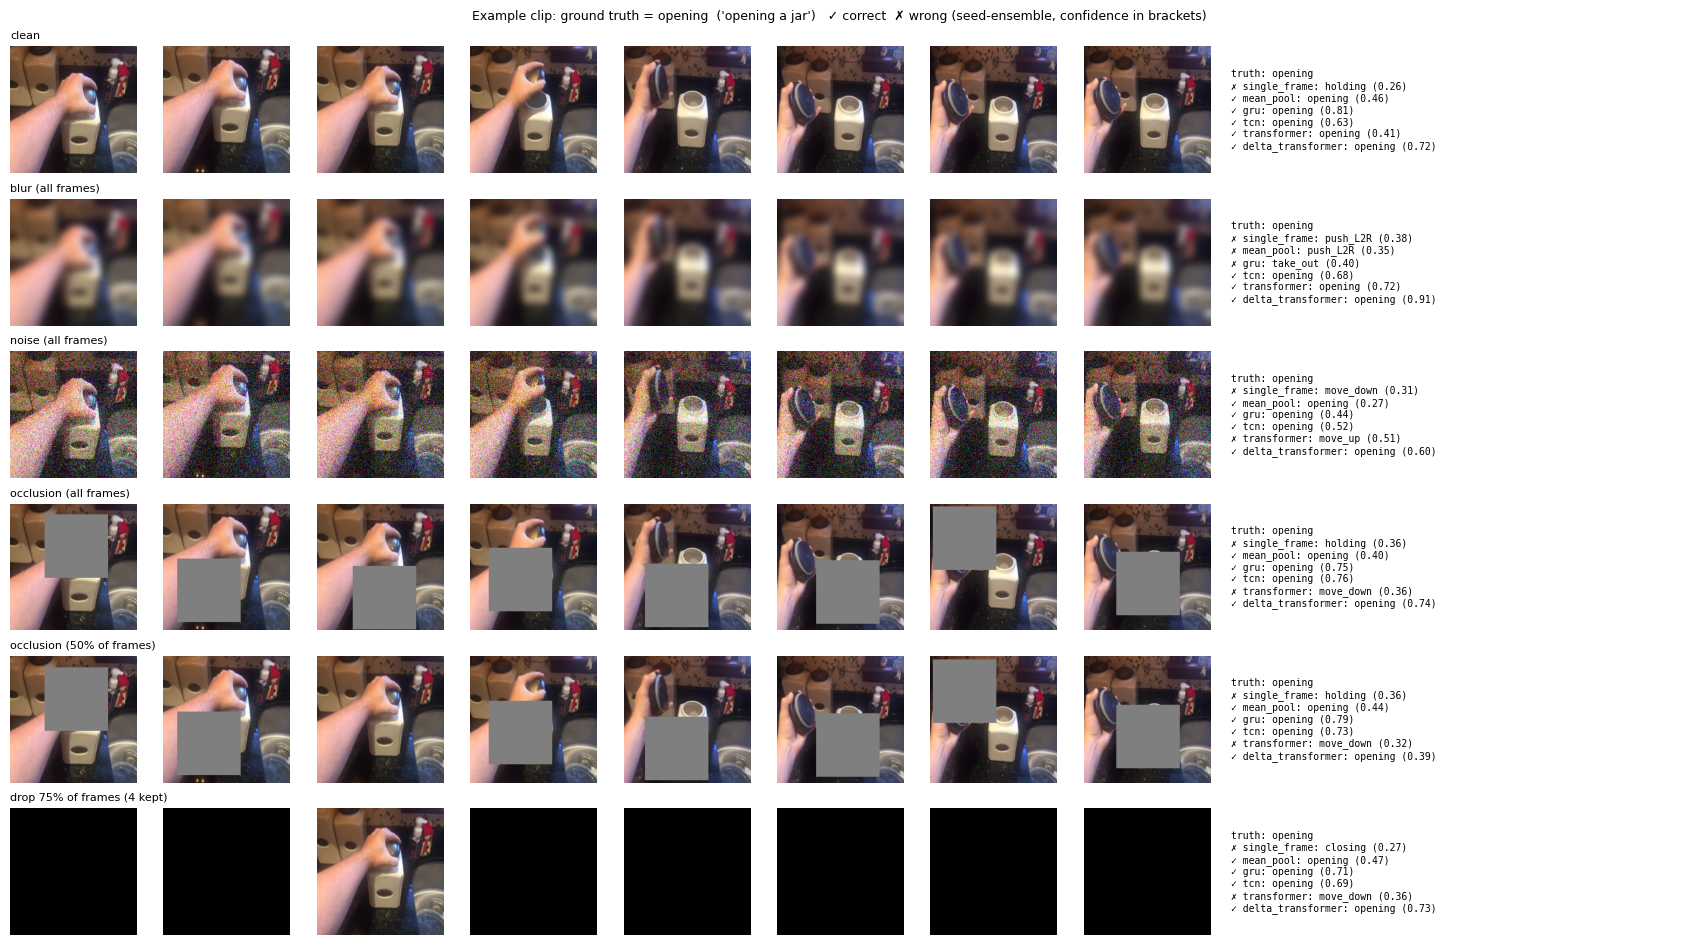

                                 single_frame        mean_pool              gru             tcn       transformer delta_transformer
condition                                                                                                                          
clean                          holding (0.26)   opening (0.46)   opening (0.81)  opening (0.63)    opening (0.41)    opening (0.72)
blur (all frames)             push_L2R (0.38)  push_L2R (0.35)  take_out (0.40)  opening (0.68)    opening (0.72)    opening (0.91)
noise (all frames)           move_down (0.31)   opening (0.27)   opening (0.44)  opening (0.52)    move_up (0.51)    opening (0.60)
occlusion (all frames)         holding (0.36)   opening (0.40)   opening (0.75)  opening (0.76)  move_down (0.36)    opening (0.74)
occlusion (50% of frames)      holding (0.36)   opening (0.44)   opening (0.79)  opening (0.73)  move_down (0.32)    opening (0.39)
drop 75% of frames (4 kept)    closing (0.27)   opening (0.47)   opening (0.

In [38]:
import matplotlib.pyplot as plt
COLS = 8; show_t = np.linspace(0, T - 1, COLS).astype(int)

@torch.no_grad()
def clip_pixels(j, fn=None, frac=1.0, seed=0):            # raw frames of test clip j -> [T,3,224,224] in 0..1, optionally corrupted
    torch.manual_seed(seed)
    x = torch.from_numpy(np.asarray(Xraw[trow[j]])).to(dev).permute(0, 3, 1, 2).float() / 255
    if fn is not None: x = torch.where((torch.rand(T, device=dev) < frac)[:, None, None, None], fn(x), x)
    return x

@torch.no_grad()
def clip_feats(x):                                         # same feature layout as Section 3 -> [1,T,D]
    h = dino(pixel_values=((x - imean) / istd).half()).last_hidden_state
    g = F.adaptive_avg_pool2d(h[:, 1:].float().reshape(T, 16, 16, -1).permute(0, 3, 1, 2), 2).flatten(2).permute(0, 2, 1).reshape(1, T, -1)
    return (torch.cat([h[:, 0].float().reshape(1, T, -1), g], -1) - mu_t) / sd_t

@torch.no_grad()
def ensemble_pred(Xe):                                     # Xe [1,m,D] -> {model: (label, confidence)} averaged over the 3 seeds
    out = {}
    for n, ms_ in FINAL.items():
        p = torch.stack([F.softmax(m(Xe), -1)[0] for m in ms_]).mean(0); out[n] = (SHORT[p.argmax().item()], p.max().item())
    return out

# pick an example: a pair-class clip where the temporal models are right and the single frame is wrong (falls back to the first pair clip)
cand = [j for j in np.where(pair_m)[0][:300]]
def ok(j):
    P = ensemble_pred(Xte[j:j + 1]); gt = SHORT[yn[j]]
    return P["gru"][0] == gt and P["delta_transformer"][0] == gt and P["single_frame"][0] != gt
J = next((j for j in cand if ok(j)), cand[0]); GT = SHORT[yn[J]]
print("clip:", J, "| ground truth:", GT, "|", V.text.values[tei[J]])

CONDS = [("clean", None, 1.0), ("blur (all frames)", c_blur, 1.0), ("noise (all frames)", c_noise, 1.0),
         ("occlusion (all frames)", c_occ, 1.0), ("occlusion (50% of frames)", c_occ, 0.5), ("drop 75% of frames (4 kept)", None, 1.0)]
fig, axes = plt.subplots(len(CONDS), COLS + 1, figsize=(COLS * 1.5 + 5, len(CONDS) * 1.6), gridspec_kw={"width_ratios": [1] * COLS + [3.2]}); rows = []
for r, (name, fn, fr) in enumerate(CONDS):
    x = clip_pixels(J, fn, fr)
    if name.startswith("drop"):
        keep = torch.rand(1, T, device=dev, generator=torch.Generator(device=dev).manual_seed(0)).topk(4).indices.sort(1).values[0]   # 4 kept frames, in order
        Xe = clip_feats(x)[:, keep]; kept = set(keep.tolist())
    else: Xe = clip_feats(x); kept = set(range(T))
    P = ensemble_pred(Xe)
    for k, t in enumerate(show_t):
        a = axes[r, k]; a.axis("off")
        a.imshow(x[t].permute(1, 2, 0).cpu().numpy() if t in kept else np.zeros((224, 224, 3)))    # dropped frames shown black
    axes[r, 0].set_title(name, fontsize=8, loc="left")
    txt = f"truth: {GT}\n" + "\n".join(f"{'✓' if P[n][0] == GT else '✗'} {n}: {P[n][0]} ({P[n][1]:.2f})" for n in NAMES5)
    axes[r, COLS].axis("off"); axes[r, COLS].text(0, 0.5, txt, fontsize=7, va="center", family="monospace")
    rows.append({"condition": name, **{n: f"{P[n][0]} ({P[n][1]:.2f})" for n in NAMES5}})
plt.suptitle(f"Example clip: ground truth = {GT}  ('{V.text.values[tei[J]]}')   ✓ correct  ✗ wrong (seed-ensemble, confidence in brackets)", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_section5_example.png", dpi=150); plt.show()
ex = pd.DataFrame(rows).set_index("condition"); print(ex.to_string()); ex.to_csv(f"{OUT}/section5_example.csv")

In [ ]:
!pip install num2words

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13781 sha256=f1f34d6419cee6cbcff916d99b825fa9fc61d63e6a137c4cd91837208edbf1c4
  Stored in directory: /root/.cache/pip/wheels/0b/1d/03/175286677fb5a1341cc3e4755bf8ec0ed08f3329afd67446b0
Successfully built docopt
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [num2words]


In [ ]:
import importlib, transformers.utils.import_utils as iu
importlib.invalidate_caches()
iu._num2words_available = True if hasattr(iu, "_num2words_available") else None
import transformers.models.smolvlm.processing_smolvlm as sp
sp.num2words = __import__("num2words").num2words

Qwen2-VL-2B: loaded saved results


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.03GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

SmolVLM2-500M:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

Qwen2-VL-2B: reversal flip rate = 0.42 (n=24) | pair clips, mean P(true class): ordered 0.232 -> reversed 0.162; mean P(partner) under reversal 0.208
SmolVLM2-500M: reversal flip rate = 0.00 (n=10) | pair clips, mean P(true class): ordered 0.118 -> reversed 0.119; mean P(partner) under reversal 0.114

== zero-shot VLM accuracy (chance 0.10) ==
        model     cond  acc    se  acc_pair  acc_static
  Qwen2-VL-2B   single 0.24 0.043     0.175        0.50
  Qwen2-VL-2B  ordered 0.33 0.047     0.300        0.45
  Qwen2-VL-2B reversed 0.23 0.042     0.175        0.45
SmolVLM2-500M   single 0.07 0.026     0.088        0.00
SmolVLM2-500M  ordered 0.10 0.030     0.125        0.00
SmolVLM2-500M reversed 0.10 0.030     0.125        0.00

embedding models on the SAME 100 clips: {'single': 0.29, 'meanpool': 0.42, 'transformer_delta': 0.55}


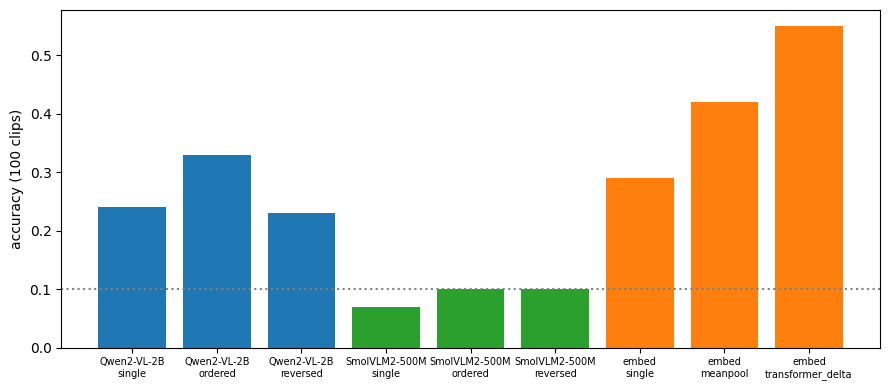


[opening]
  Qwen2-VL-2B ordered : In the first frame, a hand is seen holding a bottle of oil, and in the last frame, the hand has removed the bottle. The oil bottle is now empty. The hand's actions suggest that the oil was used or poured into the bottle, and then the hand removed it. This change
  Qwen2-VL-2B reversed: In the first frame, a hand is seen holding a small bottle of oil, and a metal object is placed on the table. In the last frame, the hand is no longer visible, and the bottle of oil is still on the table. The metal object is also no longer visible. Over time
  SmolVLM2-500M ordered : The first frame shows a hand holding a bottle of liquid, while the last frame reveals a bottle of liquid with a label, indicating a change in the contents.
  SmolVLM2-500M reversed: The first frame shows a hand holding a bottle of liquid, while the last frame reveals a bottle of liquid with a label, indicating a change in the contents.

[closing]
  Qwen2-VL-2B ordered : In the first frame, t

In [ ]:
import gc, os
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image
from transformers import AutoProcessor
try: from transformers import AutoModelForImageTextToText as AutoVLM
except ImportError: from transformers import AutoModelForMultimodalLM as AutoVLM

# ---------- sanity check: fail early with a clear message after a kernel restart
need = ["yn", "Xraw", "trow", "sel8", "T", "SHORT", "dev", "OUT", "PR", "M2", "Xte", "ens_probs"]
missing = [n for n in need if n not in globals()]
if missing: raise RuntimeError(f"Re-run the setup cells first. Missing: {missing}")

try: del dino
except NameError: pass
gc.collect(); torch.cuda.empty_cache()

VLMS = {"Qwen2-VL-2B": "Qwen/Qwen2-VL-2B-Instruct", "SmolVLM2-500M": "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"}
N_PER_CLASS = 10
OPTIONS = {"opening": "Opening something", "closing": "Closing something", "move_up": "Moving something up", "move_down": "Moving something down",
           "push_L2R": "Pushing something from left to right", "push_R2L": "Pushing something from right to left",
           "put_into": "Putting something into something", "take_out": "Taking something out of something",
           "holding": "Holding something", "showing": "Showing something to the camera"}
LET = "ABCDEFGHIJ"
o1 = list(np.random.RandomState(0).permutation(10)); ORDERS = [o1, o1[::-1]]

try: part_idx = partner.cpu().numpy() if hasattr(partner, "cpu") else np.asarray(partner)
except NameError:
    part_idx = np.array([1, 0, 3, 2, 5, 4, 7, 6, 8, 9])   # pairs (0,1)(2,3)(4,5)(6,7); 8, 9 static
    print("`partner` not found, using default pair mapping:", part_idx)

def load_vlm(mid):
    proc = AutoProcessor.from_pretrained(mid)
    dt = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    try:
        kw = dict(low_cpu_mem_usage=True, device_map={"": str(dev)})
        try: model = AutoVLM.from_pretrained(mid, dtype=dt, **kw)
        except TypeError: model = AutoVLM.from_pretrained(mid, torch_dtype=dt, **kw)
    except (ImportError, ValueError):   # no accelerate: load on CPU in half precision, then move
        try: model = AutoVLM.from_pretrained(mid, dtype=dt, low_cpu_mem_usage=True)
        except TypeError: model = AutoVLM.from_pretrained(mid, torch_dtype=dt, low_cpu_mem_usage=True)
        model = model.to(dev)
    ip = getattr(proc, "image_processor", None)
    if ip is not None and hasattr(ip, "do_image_splitting"): ip.do_image_splitting = False   # SmolVLM: one tile per frame
    return proc, model.eval(), dt

def build_msgs(n, final):
    c = [{"type": "text", "text": f"These are {n} frame(s) from a short first-person video of a hand interacting with an object, in chronological order (Frame 1 is earliest). Left/right are as seen in the images."}]
    for k in range(n): c += [{"type": "text", "text": f"Frame {k + 1}:"}, {"type": "image"}]
    return [{"role": "user", "content": c + [{"type": "text", "text": final}]}]

def make_inputs(proc, frames, final, nested, dt):
    text = proc.apply_chat_template(build_msgs(len(frames), final), add_generation_prompt=True, tokenize=False)
    pil = [Image.fromarray(np.asarray(f)) for f in frames]
    return proc(text=[text], images=[pil] if nested else pil, return_tensors="pt").to(dev, dtype=dt)   # dtype cast only touches float tensors

@torch.no_grad()
def score(proc, model, frames, order, letter_ids, nested, dt):
    opts = "\n".join(f"{LET[j]}. {OPTIONS[SHORT[c]]}" for j, c in enumerate(order))
    lg = model(**make_inputs(proc, frames, f"Which action is shown?\n{opts}\nAnswer with the letter only.", nested, dt)).logits[0, -1].float()
    p = F.softmax(torch.stack([torch.logsumexp(lg[l], 0) for l in letter_ids]), 0).cpu().numpy()
    out = np.zeros(10)
    for j, c in enumerate(order): out[c] = p[j]
    return out

@torch.no_grad()
def describe(proc, model, frames, nested, dt):
    inp = make_inputs(proc, frames, "In 2 short sentences: what changes between the first and last frame, and what becomes clear only over time?", nested, dt)
    g = model.generate(**inp, max_new_tokens=60, do_sample=False)
    return proc.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

rs = np.random.RandomState(0)
sel = np.concatenate([rs.choice(np.where(yn == c)[0], N_PER_CLASS, replace=False) for c in range(10)]); ys = yn[sel]
conds = {"single": lambda fr: [fr[T // 2]], "ordered": lambda fr: list(fr[sel8]), "reversed": lambda fr: list(fr[sel8][::-1])}
qual_ids = [sel[np.where(ys == c)[0][0]] for c in range(8)][:6]
RES, QUAL = {}, {}

for name, mid in VLMS.items():
    f_scores, f_qual = f"{OUT}/vlm_scores_{name}.npz", f"{OUT}/vlm_qual_{name}.json"
    if os.path.exists(f_scores) and os.path.exists(f_qual):          # resume after a crash
        import json
        z = np.load(f_scores); RES[name] = {c: z[c] for c in conds}
        QUAL[name] = {int(k): v for k, v in json.load(open(f_qual)).items()}
        print(f"{name}: loaded saved results"); continue
    proc, model, dt = load_vlm(mid); nested = "smol" in mid.lower(); tok = proc.tokenizer
    letter_ids = [torch.tensor([tok.encode(L, add_special_tokens=False)[0], tok.encode(" " + L, add_special_tokens=False)[0]], device=dev) for L in LET]
    RES[name] = {c: np.zeros((len(sel), 10)) for c in conds}
    for a, i in enumerate(tqdm(sel, desc=name)):
        fr = np.asarray(Xraw[trow[i]])
        for c, fn in conds.items(): RES[name][c][a] = np.mean([score(proc, model, fn(fr), o, letter_ids, nested, dt) for o in ORDERS], 0)
    QUAL[name] = {int(i): {"ordered": describe(proc, model, conds["ordered"](np.asarray(Xraw[trow[i]])), nested, dt),
                           "reversed": describe(proc, model, conds["reversed"](np.asarray(Xraw[trow[i]])), nested, dt)} for i in qual_ids}
    import json
    np.savez(f_scores, sel=sel, ys=ys, **RES[name]); json.dump({str(k): v for k, v in QUAL[name].items()}, open(f_qual, "w"))
    del model, proc; gc.collect(); torch.cuda.empty_cache()

# ---------- results
pairm = ys < 8; rows = []
for name in RES:
    for c in conds:
        P = RES[name][c].argmax(1) == ys
        rows.append(dict(model=name, cond=c, acc=P.mean(), se=np.sqrt(P.mean() * (1 - P.mean()) / len(P)), acc_pair=P[pairm].mean(), acc_static=P[~pairm].mean()))
    Po, Pr = RES[name]["ordered"], RES[name]["reversed"]; ok = (Po.argmax(1) == ys) & pairm; r = np.arange(len(ys))
    flip = (Pr.argmax(1)[ok] == part_idx[ys[ok]]).mean() if ok.sum() else float("nan")
    print(f"{name}: reversal flip rate = {flip:.2f} (n={ok.sum()}) | pair clips, mean P(true class): ordered {Po[r, ys][pairm].mean():.3f} -> reversed {Pr[r, ys][pairm].mean():.3f}; "
          f"mean P(partner) under reversal {Pr[r[pairm], part_idx[ys[pairm]]].mean():.3f}")
res = pd.DataFrame(rows).round(3); print("\n== zero-shot VLM accuracy (chance 0.10) =="); print(res.to_string(index=False)); res.to_csv(f"{OUT}/vlm_results.csv", index=False)

PR["single"] = ens_probs(M2["single"], Xte)
emb = {n: float((PR[n].argmax(1).cpu().numpy()[sel] == ys).mean()) for n in ["single", "meanpool", "transformer_delta"]}
print("\nembedding models on the SAME 100 clips:", {k: round(v, 3) for k, v in emb.items()})

plt.figure(figsize=(9, 4))
labs, vals = [], []
for name in RES:
    for c in conds: labs.append(f"{name}\n{c}"); vals.append(res[(res.model == name) & (res.cond == c)].acc.item())
for k, v in emb.items(): labs.append(f"embed\n{k}"); vals.append(v)
plt.bar(range(len(vals)), vals, color=["C0"] * 3 + ["C2"] * 3 + ["C1"] * 3); plt.xticks(range(len(vals)), labs, fontsize=7)
plt.axhline(0.1, color="gray", ls=":"); plt.ylabel("accuracy (100 clips)")
plt.tight_layout(); plt.savefig(f"{OUT}/vlm_vs_embedding.png", dpi=150); plt.show()

for i in qual_ids:
    print(f"\n[{SHORT[yn[i]]}]")
    for name in QUAL: print(f"  {name} ordered : {QUAL[name][int(i)]['ordered']}\n  {name} reversed: {QUAL[name][int(i)]['reversed']}")